In [5]:
import onnxruntime as ort
import numpy as np
import json
import uproot
import pandas as pd
import matplotlib.pyplot as plt
import mplhep
from sklearn import metrics
from scipy.integrate import simpson
from scipy.integrate import trapezoid
from scipy.stats import distributions
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import KFold
from scipy.stats import chisquare
import xgboost 
import pickle
import json
from scipy.stats import chisquare
import warnings
from collections import defaultdict #for feature imp avg
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight 
from pprint import pprint
from matplotlib.ticker import FuncFormatter  #for y-axis scaling for histograms
import matplotlib.ticker as mtick

In [6]:
# Initialize the counter
if 'execution_count' not in globals():
    execution_count = 0


In [7]:
mplhep.style.use('ATLAS')
nbins = 10

In [8]:
# KS Test
def ks_weighted(data1, data2, wei1, wei2, alternative='two-sided'):
    data1 = np.array(data1)
    data2 = np.array(data2)
    wei1 = np.array(wei1)
    wei2 = np.array(wei2)
    
    ix1 = np.argsort(data1)
    ix2 = np.argsort(data2)
    data1 = data1[ix1]
    data2 = data2[ix2]
    wei1 = wei1[ix1]
    wei2 = wei2[ix2]
    data = np.concatenate([data1, data2])
    cwei1 = np.hstack([0, np.cumsum(wei1)/sum(wei1)])
    cwei2 = np.hstack([0, np.cumsum(wei2)/sum(wei2)])
    cdf1we = cwei1[np.searchsorted(data1, data, side='right')]
    cdf2we = cwei2[np.searchsorted(data2, data, side='right')]
    d = np.max(np.abs(cdf1we - cdf2we))
    # calculate p-value
    n1 = data1.shape[0]
    n2 = data2.shape[0]
    m, n = sorted([float(n1), float(n2)], reverse=True)
    en = m * n / (m + n)
    if alternative == 'two-sided':
        prob = distributions.kstwo.sf(d, np.round(en))
    else:
        z = np.sqrt(en) * d
        # Use Hodges' suggested approximation Eqn 5.3
        # Requires m to be the larger of (n1, n2)
        expt = -2 * z**2 - 2 * z * (m + 2*n)/np.sqrt(m*n*(m+n))/3.0
        prob = np.exp(expt)
    return d, prob

In [9]:

feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                #'jet_pt[:,2]', 
                #'jet_pt[:,3]',
                #'jet_e[:,0]',
                #'jet_e[:,1]', 
                #'jet_e[:,2]', 
                #'jet_e[:,3]', 
                'met_met',
                # 'met_phi',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                #'ph_e[:,0]', 
                #'ph_e[:,1]', 
                #'ph_phi[:,0]', 
                #'ph_phi[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                #'event_njets',
                #'event_HT', 
                #'event_ST', 
                'event_nbjets70', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb70_closest[:,0]',
                'ph_mphb70_closest[:,1]',
                #'ph_drphb77_leading_pt[:,0]', 
                #'ph_drphb77_leading_pt[:,1]',
                'm_AllObjects',
                #'m_ph_bjet', 
                 #'dr_lep_bjetscore', 
                #'jet_DL1r_bjetscore',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph'
                  ]
                  


# Update the counter
global execution_count
execution_count += 1
print(f"This cell has been run {execution_count} times.")

This cell has been run 1 times.


In [10]:
len(feature_cols)

20

In [11]:
cols = feature_cols+['eventNumber','weight']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'}

In [12]:
df_sig = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [13]:
n_estimators = 100


# Older runs

In [ ]:
"""
for fold in range(nfolds):
    # Train and test sets with original weights
    sig_train_mask = df_sig_ttyy['eventNumber'] % nfolds != fold
    sig_test_mask = df_sig_ttyy['eventNumber'] % nfolds == fold
    bkg_train_mask = df_bkg_tty['eventNumber'] % nfolds != fold
    bkg_test_mask = df_bkg_tty['eventNumber'] % nfolds == fold

    X_sig_train = df_sig_ttyy[feature_cols][sig_train_mask]
    w_sig_train = df_sig_ttyy['weight'][sig_train_mask]
    X_sig_test = df_sig_ttyy[feature_cols][sig_test_mask]
    w_sig_test = df_sig_ttyy['weight'][sig_test_mask]

    X_bkg_train = df_bkg_tty[feature_cols][bkg_train_mask]
    w_bkg_train = df_bkg_tty['weight'][bkg_train_mask]
    X_bkg_test = df_bkg_tty[feature_cols][bkg_test_mask]
    w_bkg_test = df_bkg_tty['weight'][bkg_test_mask]

    # Nominal weight sums
    total_weight_nominal_train = np.sum(w_sig_train) + np.sum(w_bkg_train)
    total_weight_nominal_test = np.sum(w_sig_test) + np.sum(w_bkg_test)

    # Use absolute weights
    w_sig_train_abs = np.abs(w_sig_train)
    w_bkg_train_abs = np.abs(w_bkg_train)
    w_sig_test_abs = np.abs(w_sig_test)
    w_bkg_test_abs = np.abs(w_bkg_test)

    # Total weight sums with absolute weights
    total_weight_abs_train = np.sum(w_sig_train_abs) + np.sum(w_bkg_train_abs)
    total_weight_abs_test = np.sum(w_sig_test_abs) + np.sum(w_bkg_test_abs)

    # Compute normalization factors
    norm_factor_train = total_weight_nominal_train / total_weight_abs_train
    norm_factor_test = total_weight_nominal_test / total_weight_abs_test

    # Scale the absolute weights to match the nominal total weight
    w_sig_train_scaled = w_sig_train_abs * norm_factor_train
    w_bkg_train_scaled = w_bkg_train_abs * norm_factor_train
    w_sig_test_scaled = w_sig_test_abs * norm_factor_test
    w_bkg_test_scaled = w_bkg_test_abs * norm_factor_test

    # Concatenate signal and background for training and testing
    y_train = np.concatenate([np.ones_like(w_sig_train_scaled), np.zeros_like(w_bkg_train_scaled)])
    X_train = np.concatenate([X_sig_train, X_bkg_train])
    w_train = np.concatenate([w_sig_train_scaled, w_bkg_train_scaled])

    y_test = np.concatenate([np.ones_like(w_sig_test_scaled), np.zeros_like(w_bkg_test_scaled)])
    X_test = np.concatenate([X_sig_test, X_bkg_test])
    w_test = np.concatenate([w_sig_test_scaled, w_bkg_test_scaled])

    # Proceed with XGBoost or any other model training using X_train, y_train, w_train

"""

In [52]:
# Current model with no reweighting
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg['weight'][df_bkg['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg['weight'][df_bkg['eventNumber']%nfolds == fold]
    

    print("Signal train values:", X_sig_train[0:1])
 
    # Nominal weight sums
    total_weight_nominal_train = np.sum(w_sig_train) + np.sum(w_bkg_train)
    total_weight_nominal_test = np.sum(w_sig_test) + np.sum(w_bkg_test)

    print(f'Nominal train weights {fold}:', total_weight_nominal_train)
    print(f'Nominal test weights {fold}:', total_weight_nominal_test)

    # Use absolute weights
    w_sig_train_abs = np.abs(w_sig_train)
    w_bkg_train_abs = np.abs(w_bkg_train)
    w_sig_test_abs = np.abs(w_sig_test)
    w_bkg_test_abs = np.abs(w_bkg_test)

    # Total weight sums with absolute weights
    total_weight_abs_train = np.sum(w_sig_train_abs) + np.sum(w_bkg_train_abs)
    total_weight_abs_test = np.sum(w_sig_test_abs) + np.sum(w_bkg_test_abs)

    print(f'Absolute train weights {fold}:', total_weight_abs_train)
    print(f'Absolute test weights {fold}:', total_weight_abs_test)
    
    
    # Compute normalization factors
    norm_factor_train = total_weight_nominal_train / total_weight_abs_train
    norm_factor_test = total_weight_nominal_test / total_weight_abs_test

    print(f'Norm factors (train, test):',norm_factor_train, norm_factor_test)
    
    # Scale the absolute weights to match the nominal total weight
    w_sig_train_scaled = w_sig_train_abs * norm_factor_train
    w_bkg_train_scaled = w_bkg_train_abs * norm_factor_train
    w_sig_test_scaled = w_sig_test_abs * norm_factor_test
    w_bkg_test_scaled = w_bkg_test_abs * norm_factor_test

    y_train =  np.concatenate([np.ones_like(w_sig_train_scaled),np.zeros_like(w_bkg_train_scaled)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train_scaled,w_bkg_train_scaled])
    y_test  =  np.concatenate([np.ones_like(w_sig_test_scaled),np.zeros_like(w_bkg_test_scaled)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test_scaled,w_bkg_test_scaled])
    
    print("Lengths of train and test sets:")
    print("Signal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test(events,weights): ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    print("prediction train test: ", len(y_train), len(y_test))
    print("prediction values: ", y_train[-100:], y_test[-100:])
    #print("concatenated train test: ", len(X_train), len(X_test))
    #print("concatenated train test values: ", X_train[0:2], X_test[0:2])

    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

Signal train values:         jet_pt[:,0]   jet_pt[:,1]       met_met  ph_eta[:,0]  ph_eta[:,1]  \
entry                                                                       
0      150484.40625  73511.679688  94067.289062    -0.810186    -2.244604   

         ph_pt[:,0]    ph_pt[:,1]  ph_mlph_closest[:,0]  ph_mlph_closest[:,1]  \
entry                                                                           
0      69320.984375  40159.082031           111921.4375          85738.242188   

             diph_M  event_nbjets70  dr_lep_ph0  dr_lep_ph1  \
entry                                                         
0      133776.86572               1    1.696234    2.024914   

       ph_conversion_type[:,1]  ph_conversion_type[:,0]  \
entry                                                     
0                            0                        0   

       ph_mphb70_closest[:,0]  ph_mphb70_closest[:,1]   m_AllObjects  \
entry                                                          

Train scores 3: [0.7234571127507617, 0.7249286427135917, 0.7282670988886248, 0.7304599428017032]
Test scores 3:  [0.6320547835949811, 0.6690286133248075, 0.6604450151687211, 0.6308523528534313]
100


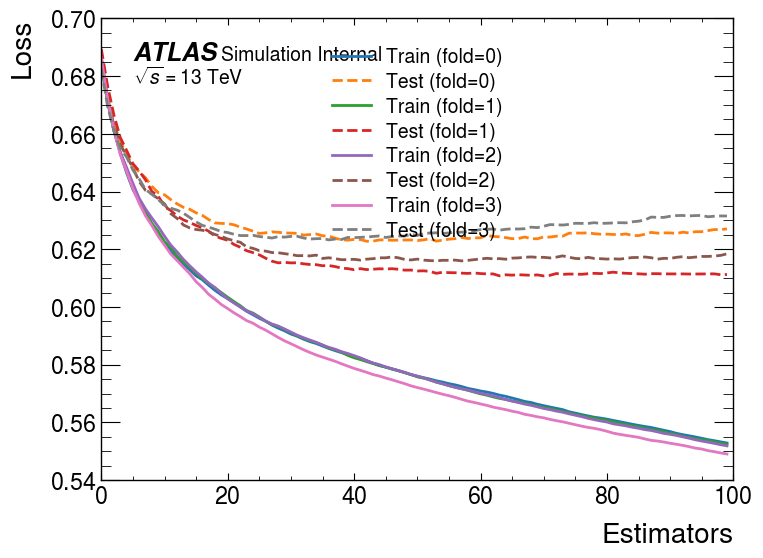

In [53]:
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [54]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.507212  , 0.5112174 , 0.7557495 , ..., 0.75184435, 0.7303224 ,
       0.56534284], dtype=float32), array([0.52361774, 0.5524807 , 0.7583828 , ..., 0.6344437 , 0.71938455,
       0.56858075], dtype=float32), array([0.57554495, 0.56774014, 0.763143  , ..., 0.79510534, 0.708205  ,
       0.7284748 ], dtype=float32), array([0.46444434, 0.51890916, 0.70908135, ..., 0.7481279 , 0.7550454 ,
       0.67525274], dtype=float32)]
Bkg:  [array([0.37759385, 0.56590164, 0.6510345 , ..., 0.58520293, 0.33336645,
       0.6551007 ], dtype=float32), array([0.31573504, 0.5083383 , 0.69105834, ..., 0.16633295, 0.35064793,
       0.66618454], dtype=float32), array([0.44303873, 0.46673653, 0.6247589 , ..., 0.16007195, 0.32099074,
       0.650389  ], dtype=float32), array([0.37159765, 0.6091612 , 0.6996289 , ..., 0.1842498 , 0.5318287 ,
       0.6544172 ], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3959


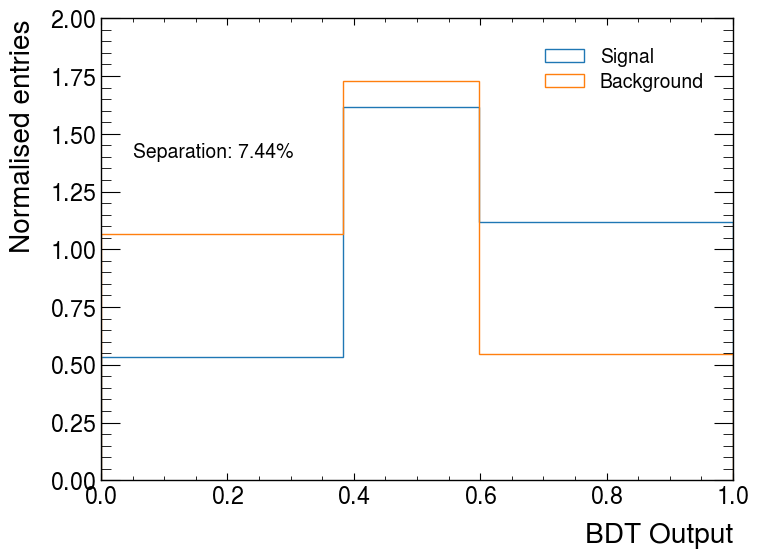

In [55]:
# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.4, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.png')
plt.legend()

sig histogram values:  [0.01112423 0.31311457 0.77721026 1.15470857 1.50922643 1.78444047
 1.89587865 1.6931433  0.81216678 0.0489864 ]


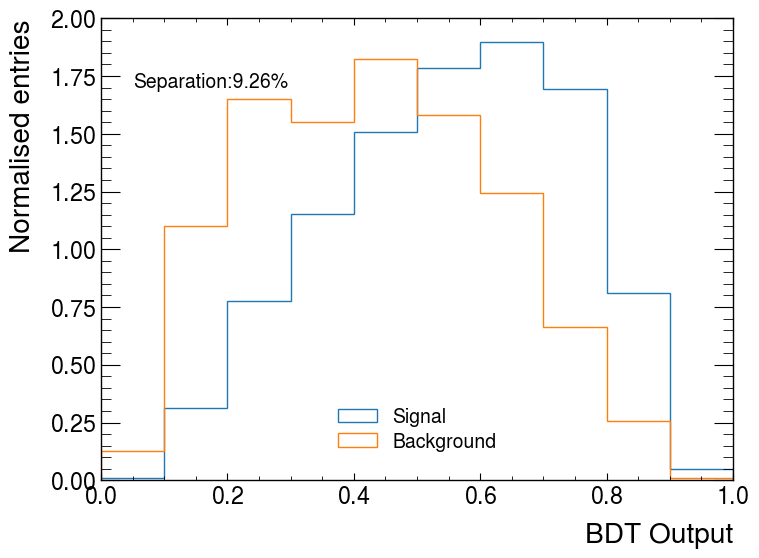

In [56]:
# Considering Negative Weights
nbins = 10
bc_sig,_,_ = plt.hist(results_sig, weights=(df_sig['weight']),  range=(0,1), bins=nbins, histtype='step', density=True, label='Signal')
bc_bkg,_,_ = plt.hist(results_bkg, weights=(df_bkg['weight']), range=(0,1), bins=nbins, histtype='step', density=True, label='Background')
print('sig histogram values: ',bc_sig )
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig/nbins - bc_bkg/nbins) ** 2) / (bc_sig/nbins + bc_bkg/nbins)))

plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
#mplhep.atlas.label('WIP', data=False, ax=ax)
plt.text(x=0.05, y=1.7,s=F'Separation:{separation*100:.2f}%')

plt.legend()

In [ ]:
"""
for fold in range(nfolds):
    # Train and test sets for signal
    sig_train_mask = df_sig_ttyy['eventNumber'] % nfolds != fold
    sig_test_mask = df_sig_ttyy['eventNumber'] % nfolds == fold

    X_sig_train = df_sig_ttyy[feature_cols][sig_train_mask]
    w_sig_train = df_sig_ttyy['weight'][sig_train_mask]
    X_sig_test = df_sig_ttyy[feature_cols][sig_test_mask]
    w_sig_test = df_sig_ttyy['weight'][sig_test_mask]

    # Train and test sets for background
    bkg_train_mask = df_bkg_tty['eventNumber'] % nfolds != fold
    bkg_test_mask = df_bkg_tty['eventNumber'] % nfolds == fold

    X_bkg_train = df_bkg_tty[feature_cols][bkg_train_mask]
    w_bkg_train = df_bkg_tty['weight'][bkg_train_mask]
    X_bkg_test = df_bkg_tty[feature_cols][bkg_test_mask]
    w_bkg_test = df_bkg_tty['weight'][bkg_test_mask]

    # Nominal background weight sums
    total_bkg_weight_nominal_train = np.sum(w_bkg_train)
    total_bkg_weight_nominal_test = np.sum(w_bkg_test)

    # Absolute background weights
    w_bkg_train_abs = np.abs(w_bkg_train)
    w_bkg_test_abs = np.abs(w_bkg_test)

    # Sum of absolute weights for background
    total_bkg_weight_abs_train = np.sum(w_bkg_train_abs)
    total_bkg_weight_abs_test = np.sum(w_bkg_test_abs)

    # Normalization factors for background weights
    norm_factor_bkg_train = total_bkg_weight_nominal_train / total_bkg_weight_abs_train
    norm_factor_bkg_test = total_bkg_weight_nominal_test / total_bkg_weight_abs_test

    # Scale background weights to maintain nominal background normalization
    w_bkg_train_scaled = w_bkg_train_abs * norm_factor_bkg_train
    w_bkg_test_scaled = w_bkg_test_abs * norm_factor_bkg_test

    # Combine signal and background data
    y_train = np.concatenate([np.ones_like(w_sig_train), np.zeros_like(w_bkg_train_scaled)])
    X_train = np.concatenate([X_sig_train, X_bkg_train])
    w_train = np.concatenate([w_sig_train, w_bkg_train_scaled])

    y_test = np.concatenate([np.ones_like(w_sig_test), np.zeros_like(w_bkg_test_scaled)])
    X_test = np.concatenate([X_sig_test, X_bkg_test])
    w_test = np.concatenate([w_sig_test, w_bkg_test_scaled])

    # Proceed with XGBoost or other model training using X_train, y_train, w_train

"""


In [70]:
# Doing it by scaling (all) the background weights from absolute to nominal normalisation and then using them in training

n_estimators = 80
# Current model with no reweighting
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg['weight'][df_bkg['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg['weight'][df_bkg['eventNumber']%nfolds == fold]
    

    print("Signal train values:", X_sig_train[0:1])

    # Nominal background weight sums
    total_bkg_weight_nominal_train = np.sum(w_bkg_train)
    total_bkg_weight_nominal_test = np.sum(w_bkg_test)

    # Absolute background weights
    w_bkg_train_abs = np.abs(w_bkg_train)
    w_bkg_test_abs = np.abs(w_bkg_test)

    # Sum of absolute weights for background
    total_bkg_weight_abs_train = np.sum(w_bkg_train_abs)
    total_bkg_weight_abs_test = np.sum(w_bkg_test_abs)

    # Normalization factors for background weights
    norm_factor_bkg_train = total_bkg_weight_nominal_train / total_bkg_weight_abs_train
    norm_factor_bkg_test = total_bkg_weight_nominal_test / total_bkg_weight_abs_test

    # Scale background weights to maintain nominal background normalization
    w_bkg_train_scaled = w_bkg_train_abs * norm_factor_bkg_train
    w_bkg_test_scaled = w_bkg_test_abs * norm_factor_bkg_test
    
    print(f'Norm factors (train, test):',norm_factor_bkg_train, norm_factor_bkg_test)

    #no need --> print('Weighting factors: ',w_bkg_train_scaled, w_bkg_test_scaled)

    # Combine signal and background data
    y_train = np.concatenate([np.ones_like(w_sig_train), np.zeros_like(w_bkg_train_scaled)])
    X_train = np.concatenate([X_sig_train, X_bkg_train])
    w_train = np.concatenate([w_sig_train, w_bkg_train_scaled])

    y_test = np.concatenate([np.ones_like(w_sig_test), np.zeros_like(w_bkg_test_scaled)])
    X_test = np.concatenate([X_sig_test, X_bkg_test])
    w_test = np.concatenate([w_sig_test, w_bkg_test_scaled])
    
    print("Lengths of train and test sets:")
    print("Signal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test(events,weights): ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    print("prediction train test: ", len(y_train), len(y_test))
    print("prediction values: ", y_train[-100:], y_test[-100:])
    #print("concatenated train test: ", len(X_train), len(X_test))
    #print("concatenated train test values: ", X_train[0:2], X_test[0:2])

    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

Signal train values:         jet_pt[:,0]   jet_pt[:,1]       met_met  ph_eta[:,0]  ph_eta[:,1]  \
entry                                                                       
0      150484.40625  73511.679688  94067.289062    -0.810186    -2.244604   

         ph_pt[:,0]    ph_pt[:,1]  ph_mlph_closest[:,0]  ph_mlph_closest[:,1]  \
entry                                                                           
0      69320.984375  40159.082031           111921.4375          85738.242188   

             diph_M  event_nbjets70  dr_lep_ph0  dr_lep_ph1  \
entry                                                         
0      133776.86572               1    1.696234    2.024914   

       ph_conversion_type[:,1]  ph_conversion_type[:,0]  \
entry                                                     
0                            0                        0   

       ph_mphb70_closest[:,0]  ph_mphb70_closest[:,1]   m_AllObjects  \
entry                                                          

Train scores 3: [0.7201371974073393, 0.7174676792001791, 0.719126092742584, 0.7203464641415934]
Test scores 3:  [0.6498427298136538, 0.6781620699347037, 0.6630875691729996, 0.6552928072916276]
80


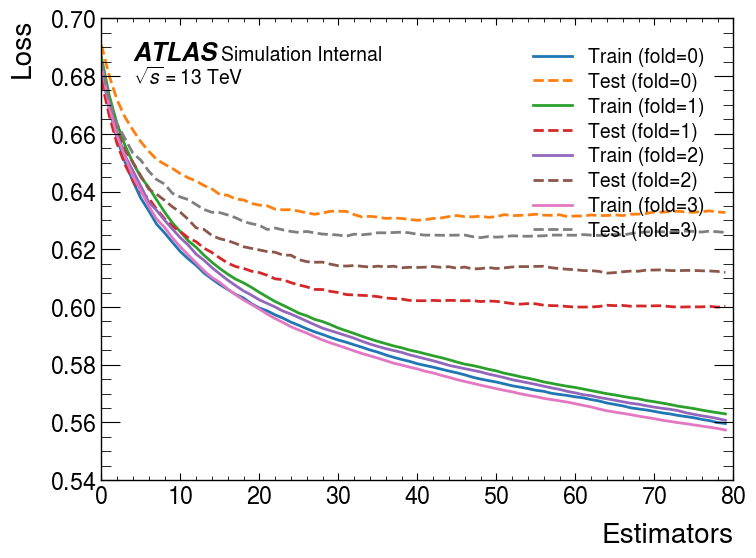

In [71]:
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [72]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.58202094, 0.65825117, 0.8526673 , ..., 0.7472594 , 0.791188  ,
       0.69029063], dtype=float32), array([0.6090221 , 0.6366579 , 0.8418507 , ..., 0.81430715, 0.83635014,
       0.6639114 ], dtype=float32), array([0.6654627 , 0.66956437, 0.8664513 , ..., 0.8823058 , 0.7810713 ,
       0.73856986], dtype=float32), array([0.66003096, 0.6575835 , 0.8124961 , ..., 0.8443112 , 0.8536301 ,
       0.7205384 ], dtype=float32)]
Bkg:  [array([0.52814865, 0.6464575 , 0.7857649 , ..., 0.7492277 , 0.445679  ,
       0.77521336], dtype=float32), array([0.4246379 , 0.6352411 , 0.82077533, ..., 0.25365224, 0.514386  ,
       0.8375289 ], dtype=float32), array([0.51077014, 0.587347  , 0.778757  , ..., 0.25172627, 0.48088634,
       0.73978376], dtype=float32), array([0.50798345, 0.6220389 , 0.81248164, ..., 0.27191404, 0.6323218 ,
       0.7683425 ], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3959


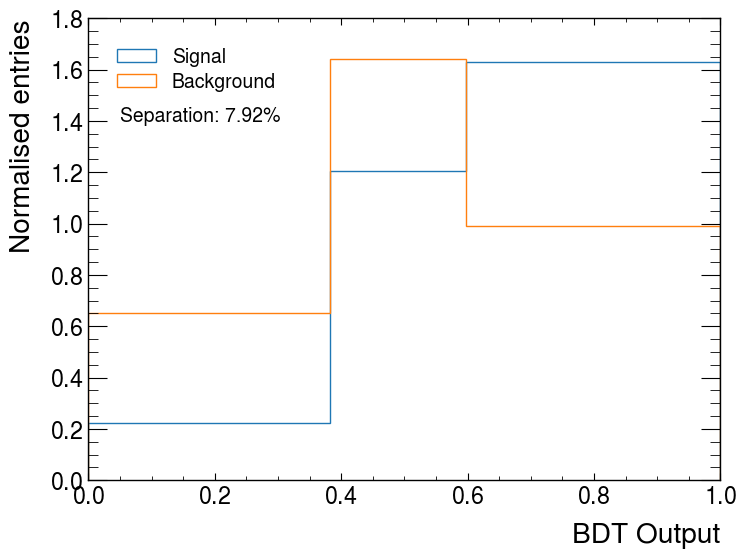

In [73]:
# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.4, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.png')
plt.legend()

# With separate backgrounds

In [14]:

df_sig = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)

df_bkg_ttyprod = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgamma_NLO*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)

df_bkg_ttydec = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgamma_LO*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)

df_bkg_Vyy = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [ ]:
"""
for fold in range(nfolds):
    # Background 1: Apply condition for positive weights and normalization factor
    bkg1_train_mask = (df_bkg1['eventNumber'] % nfolds != fold) & (df_bkg1['weight'] > 0)
    bkg1_test_mask = (df_bkg1['eventNumber'] % nfolds == fold) & (df_bkg1['weight'] > 0)

    # Select train and test sets for bkg1
    X_bkg1_train = df_bkg1[feature_cols][bkg1_train_mask]
    w_bkg1_train = df_bkg1['weight'][bkg1_train_mask]
    
    X_bkg1_test = df_bkg1[feature_cols][bkg1_test_mask]
    w_bkg1_test = df_bkg1['weight'][bkg1_test_mask]

    # Apply normalization factor to bkg1 weights (if needed)
    normalization_factor_bkg1 = 1.5  # Example normalization factor (change as per requirement)
    w_bkg1_train_scaled = w_bkg1_train * normalization_factor_bkg1
    w_bkg1_test_scaled = w_bkg1_test * normalization_factor_bkg1

    # Background 2: No special conditions, just select training and testing sets
    bkg2_train_mask = df_bkg2['eventNumber'] % nfolds != fold
    bkg2_test_mask = df_bkg2['eventNumber'] % nfolds == fold

    # Select train and test sets for bkg2
    X_bkg2_train = df_bkg2[feature_cols][bkg2_train_mask]
    w_bkg2_train = df_bkg2['weight'][bkg2_train_mask]
    
    X_bkg2_test = df_bkg2[feature_cols][bkg2_test_mask]
    w_bkg2_test = df_bkg2['weight'][bkg2_test_mask]

    # Concatenate bkg1 and bkg2 for the final training and testing sets
    X_bkg_train = np.concatenate([X_bkg1_train, X_bkg2_train])
    w_bkg_train = np.concatenate([w_bkg1_train_scaled, w_bkg2_train])

    X_bkg_test = np.concatenate([X_bkg1_test, X_bkg2_test])
    w_bkg_test = np.concatenate([w_bkg1_test_scaled, w_bkg2_test])

    # Continue with the rest of the training process by combining signal and background

"""

# Scaling absolute to nominal - tty prod only

In [94]:

# Doing it by scaling the background weights from absolute to nominal normalisation and then using them in training

n_estimators = 100
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]

    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    
    # Background 1
    bkgttyprod_train_mask = (df_bkg_ttyprod['eventNumber'] % nfolds != fold) #& (df_bkg_ttyprod['weight'] > 0)
    bkgttyprod_test_mask = (df_bkg_ttyprod['eventNumber'] % nfolds == fold) #& (df_bkg_ttyprod['weight'] > 0)

    # Select train and test sets for bkg1
    X_bkg1_train = df_bkg_ttyprod[feature_cols][bkgttyprod_train_mask]
    w_bkg1_train = df_bkg_ttyprod['weight'][bkgttyprod_train_mask]
    
    X_bkg1_test = df_bkg_ttyprod[feature_cols][bkgttyprod_test_mask]
    w_bkg1_test = df_bkg_ttyprod['weight'][bkgttyprod_test_mask]

    
    # Nominal background weight sums
    total_bkg_ttyprod_weight_nominal_train = np.sum(w_bkg1_train)
    total_bkg_ttyprod_weight_nominal_test = np.sum(w_bkg1_test)

    # Absolute background weights
    w_bkg_ttyprod_train_abs = np.abs(w_bkg1_train)
    w_bkg_ttyprod_test_abs = np.abs(w_bkg1_test)

    # Sum of absolute weights for background
    total_bkg_weight_abs_train = np.sum(w_bkg_ttyprod_train_abs)
    total_bkg_weight_abs_test = np.sum(w_bkg_ttyprod_test_abs)

    # Normalization factors for background weights 
    norm_factor_bkg_train = total_bkg_ttyprod_weight_nominal_train / total_bkg_weight_abs_train 
    norm_factor_bkg_test = total_bkg_ttyprod_weight_nominal_test / total_bkg_weight_abs_test
    
    print('Normalisation factors (train, test): ',norm_factor_bkg_train, norm_factor_bkg_test ) # Normalisation factors (train, test): around 0.40 0.40 
    
    # Scale background weights to maintain nominal background normalization by multiplying with nom/abs scale
    w_bkg_train_scaled = w_bkg_ttyprod_train_abs * norm_factor_bkg_train
    w_bkg_test_scaled = w_bkg_ttyprod_test_abs * norm_factor_bkg_test
    

    
    X_bkg2_train = df_bkg_ttydec[feature_cols][df_bkg_ttydec['eventNumber']%nfolds != fold]
    w_bkg2_train = df_bkg_ttydec['weight'][df_bkg_ttydec['eventNumber']%nfolds != fold]

    X_bkg2_test = df_bkg_ttydec[feature_cols][df_bkg_ttydec['eventNumber']%nfolds == fold]
    w_bkg2_test = df_bkg_ttydec['weight'][df_bkg_ttydec['eventNumber']%nfolds == fold]   

      
        
        
    X_bkg3_train = df_bkg_Vyy[feature_cols][df_bkg_Vyy['eventNumber']%nfolds != fold]
    w_bkg3_train = df_bkg_Vyy['weight'][df_bkg_Vyy['eventNumber']%nfolds != fold]

    X_bkg3_test = df_bkg_Vyy[feature_cols][df_bkg_Vyy['eventNumber']%nfolds == fold]
    w_bkg3_test = df_bkg_Vyy['weight'][df_bkg_Vyy['eventNumber']%nfolds == fold]   

    
    X_bkg_train = np.concatenate([X_bkg1_train, X_bkg2_train, X_bkg3_train])
    w_bkg_train = np.concatenate([w_bkg_train_scaled, w_bkg2_train, w_bkg3_train])

    X_bkg_test = np.concatenate([X_bkg1_test, X_bkg2_test, X_bkg3_test])
    w_bkg_test = np.concatenate([w_bkg_test_scaled, w_bkg2_test, w_bkg3_test])  


    print("Signal train values:", X_sig_train[0:1])

    #no need --> print('Weighting factors: ',w_bkg_train_scaled, w_bkg_test_scaled)

    # Combine signal and background data
    y_train = np.concatenate([np.ones_like(w_sig_train), np.zeros_like(w_bkg_train)])
    X_train = np.concatenate([X_sig_train, X_bkg_train])
    w_train = np.concatenate([w_sig_train, w_bkg_train])

    y_test = np.concatenate([np.ones_like(w_sig_test), np.zeros_like(w_bkg_test)])
    X_test = np.concatenate([X_sig_test, X_bkg_test])
    w_test = np.concatenate([w_sig_test, w_bkg_test])
    
    print("Lengths of train and test sets:")
    print("Signal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test(events,weights): ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    #print("prediction train test: ", len(y_train), len(y_test))
    #print("prediction values: ", y_train[-100:], y_test[-100:])
    #print("concatenated train test: ", len(X_train), len(X_test))
    #print("concatenated train test values: ", X_train[0:2], X_test[0:2])

    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    



Normalisation factors (train, test):  0.41093063 0.43087274
Signal train values:         jet_pt[:,0]   jet_pt[:,1]       met_met  ph_eta[:,0]  ph_eta[:,1]  \
entry                                                                       
0      150484.40625  73511.679688  94067.289062    -0.810186    -2.244604   

         ph_pt[:,0]    ph_pt[:,1]  ph_mlph_closest[:,0]  ph_mlph_closest[:,1]  \
entry                                                                           
0      69320.984375  40159.082031           111921.4375          85738.242188   

             diph_M  event_nbjets70  dr_lep_ph0  dr_lep_ph1  \
entry                                                         
0      133776.86572               1    1.696234    2.024914   

       ph_conversion_type[:,1]  ph_conversion_type[:,0]  \
entry                                                     
0                            0                        0   

       ph_mphb70_closest[:,0]  ph_mphb70_closest[:,1]   m_AllObjects  \
ent

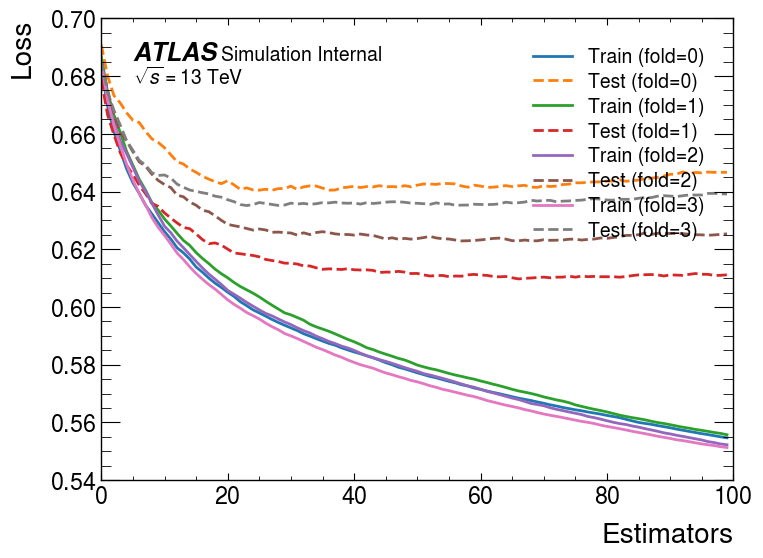

In [95]:
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [96]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.7164257 , 0.6072407 , 0.6958732 , ..., 0.78772396, 0.8094844 ,
       0.6753984 ], dtype=float32), array([0.683426  , 0.57214063, 0.6941592 , ..., 0.8234646 , 0.7566761 ,
       0.6137182 ], dtype=float32), array([0.7379482 , 0.6087303 , 0.76262665, ..., 0.8497431 , 0.82014775,
       0.7158826 ], dtype=float32), array([0.67384183, 0.61003584, 0.733464  , ..., 0.7576742 , 0.8308248 ,
       0.72529256], dtype=float32)]
Bkg:  [array([0.45109114, 0.68969077, 0.77118856, ..., 0.73234564, 0.27293643,
       0.7755185 ], dtype=float32), array([0.4028697 , 0.6244344 , 0.80620575, ..., 0.12694371, 0.4276084 ,
       0.8290995 ], dtype=float32), array([0.5372378 , 0.6960209 , 0.7619792 , ..., 0.13403334, 0.35610485,
       0.68902713], dtype=float32), array([0.40851715, 0.6234797 , 0.77512485, ..., 0.14940089, 0.52905136,
       0.7289135 ], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3959


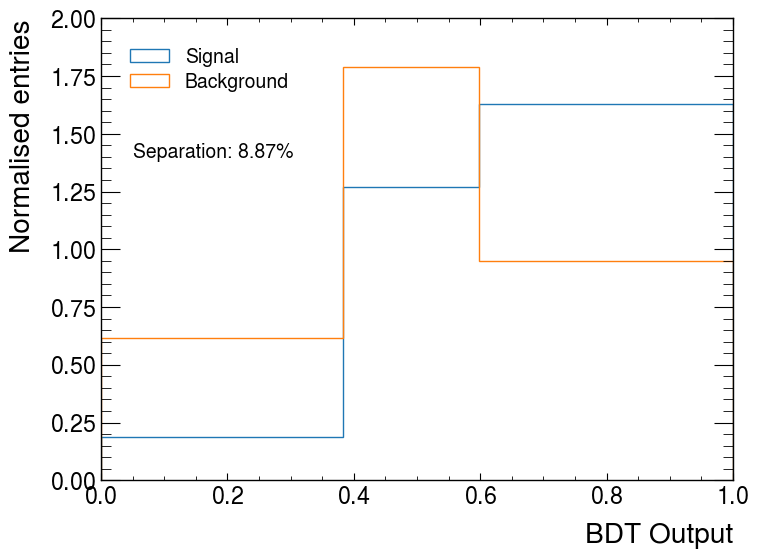

In [97]:
# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.4, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.png')
plt.legend()

# 1.Scaling absolute to nominal - all backgrounds

In [9]:

# Doing it by scaling (all) the background weights from absolute to nominal normalisation and then using them in training

n_estimators = 100
# Current model with no reweighting
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]

    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    # normalisation for tty prod
    
    # Background 1: Apply condition for positive weights and normalization factor
    bkgttyprod_train_mask = (df_bkg_ttyprod['eventNumber'] % nfolds != fold) #& (df_bkg_ttyprod['weight'] > 0)
    bkgttyprod_test_mask = (df_bkg_ttyprod['eventNumber'] % nfolds == fold) #& (df_bkg_ttyprod['weight'] > 0)

    # Select train and test sets for bkg1
    X_bkg1_train = df_bkg_ttyprod[feature_cols][bkgttyprod_train_mask]
    w_bkg1_train = df_bkg_ttyprod['weight'][bkgttyprod_train_mask]
    
    X_bkg1_test = df_bkg_ttyprod[feature_cols][bkgttyprod_test_mask]
    w_bkg1_test = df_bkg_ttyprod['weight'][bkgttyprod_test_mask]

    
    # Nominal background weight sums
    total_bkg_ttyprod_weight_nominal_train = np.sum(w_bkg1_train)
    total_bkg_ttyprod_weight_nominal_test = np.sum(w_bkg1_test)

    # Absolute background weights
    w_bkg_ttyprod_train_abs = np.abs(w_bkg1_train)
    w_bkg_ttyprod_test_abs = np.abs(w_bkg1_test)

    # Sum of absolute weights for background
    total_bkg_weight_abs_train = np.sum(w_bkg_ttyprod_train_abs)
    total_bkg_weight_abs_test = np.sum(w_bkg_ttyprod_test_abs)

    # Normalization factors for background weights
    norm_factor_bkg_train = total_bkg_ttyprod_weight_nominal_train / total_bkg_weight_abs_train 
    norm_factor_bkg_test = total_bkg_ttyprod_weight_nominal_test / total_bkg_weight_abs_test
    
    print('Normalisation factors (train, test): ',norm_factor_bkg_train, norm_factor_bkg_test ) # Normalisation factors (train, test): around 0.40 0.40 
    
    # Scale background weights to maintain nominal background normalization by multiplying with nom/abs scale
    w_bkg_train_scaled_ttyprod = w_bkg_ttyprod_train_abs * norm_factor_bkg_train
    w_bkg_test_scaled_ttyprod = w_bkg_ttyprod_test_abs * norm_factor_bkg_test
    
    #---------------------  

 


    # normalisation for tty dec

    
    X_bkg2_train = df_bkg_ttydec[feature_cols][df_bkg_ttydec['eventNumber']%nfolds != fold]
    w_bkg2_train = df_bkg_ttydec['weight'][df_bkg_ttydec['eventNumber']%nfolds != fold]

    X_bkg2_test = df_bkg_ttydec[feature_cols][df_bkg_ttydec['eventNumber']%nfolds == fold]
    w_bkg2_test = df_bkg_ttydec['weight'][df_bkg_ttydec['eventNumber']%nfolds == fold]   

   
    # Nominal background weight sums
    total_bkg_ttydec_weight_nominal_train = np.sum(w_bkg2_train)
    total_bkg_ttydec_weight_nominal_test = np.sum(w_bkg2_test)

    # Absolute background weights
    w_bkg_ttydec_train_abs = np.abs(w_bkg2_train)
    w_bkg_ttydec_test_abs = np.abs(w_bkg2_test)

    # Sum of absolute weights for background
    total_bkg_weight_abs_train = np.sum(w_bkg_ttydec_train_abs)
    total_bkg_weight_abs_test = np.sum(w_bkg_ttydec_test_abs)

    # Normalization factors for background weights
    norm_factor_bkg_train = total_bkg_ttydec_weight_nominal_train / total_bkg_weight_abs_train 
    norm_factor_bkg_test = total_bkg_ttydec_weight_nominal_test / total_bkg_weight_abs_test
    
    print('Normalisation factors (train, test): ',norm_factor_bkg_train, norm_factor_bkg_test ) # Normalisation factors (train, test): around 0.40 0.40 
    
    # Scale background weights to maintain nominal background normalization by multiplying with nom/abs scale
    w_bkg_train_scaled_ttydec = w_bkg_ttydec_train_abs * norm_factor_bkg_train
    w_bkg_test_scaled_ttydec = w_bkg_ttydec_test_abs * norm_factor_bkg_test
    
    #---------------------  

    
     # normalisation for tty dec

    
        
    X_bkg3_train = df_bkg_Vyy[feature_cols][df_bkg_Vyy['eventNumber']%nfolds != fold]
    w_bkg3_train = df_bkg_Vyy['weight'][df_bkg_Vyy['eventNumber']%nfolds != fold]

    X_bkg3_test = df_bkg_Vyy[feature_cols][df_bkg_Vyy['eventNumber']%nfolds == fold]
    w_bkg3_test = df_bkg_Vyy['weight'][df_bkg_Vyy['eventNumber']%nfolds == fold]   
   
    # Nominal background weight sums
    total_bkg_Vyy_weight_nominal_train = np.sum(w_bkg3_train)
    total_bkg_Vyy_weight_nominal_test = np.sum(w_bkg3_test)

    # Absolute background weights
    w_bkg_Vyy_train_abs = np.abs(w_bkg3_train)
    w_bkg_Vyy_test_abs = np.abs(w_bkg3_test)

    # Sum of absolute weights for background
    total_bkg_weight_abs_train = np.sum(w_bkg_Vyy_train_abs)
    total_bkg_weight_abs_test = np.sum(w_bkg_Vyy_test_abs)

    # Normalization factors for background weights
    norm_factor_bkg_train = total_bkg_Vyy_weight_nominal_train / total_bkg_weight_abs_train 
    norm_factor_bkg_test = total_bkg_Vyy_weight_nominal_test / total_bkg_weight_abs_test
    
    print('Normalisation factors (train, test): ',norm_factor_bkg_train, norm_factor_bkg_test ) # Normalisation factors (train, test): around 0.40 0.40 
    
    # Scale background weights to maintain nominal background normalization by multiplying with nom/abs scale
    w_bkg_train_scaled_Vyy = w_bkg_Vyy_train_abs * norm_factor_bkg_train
    w_bkg_test_scaled_Vyy = w_bkg_Vyy_test_abs * norm_factor_bkg_test
    


    #---------------------  

    
    X_bkg_train = np.concatenate([X_bkg1_train, X_bkg2_train, X_bkg3_train])
    w_bkg_train = np.concatenate([w_bkg_train_scaled_ttyprod, w_bkg_train_scaled_ttydec, w_bkg_train_scaled_Vyy])

    X_bkg_test = np.concatenate([X_bkg1_test, X_bkg2_test, X_bkg3_test])
    w_bkg_test = np.concatenate([w_bkg_test_scaled_ttyprod, w_bkg_test_scaled_ttydec, w_bkg_test_scaled_Vyy])  


    #print("Signal train values:", X_sig_train[0:1])

    #no need --> print('Weighting factors: ',w_bkg_train_scaled, w_bkg_test_scaled)

    # Combine signal and background data
    y_train = np.concatenate([np.ones_like(w_sig_train), np.zeros_like(w_bkg_train)])
    X_train = np.concatenate([X_sig_train, X_bkg_train])
    w_train = np.concatenate([w_sig_train, w_bkg_train])

    y_test = np.concatenate([np.ones_like(w_sig_test), np.zeros_like(w_bkg_test)])
    X_test = np.concatenate([X_sig_test, X_bkg_test])
    w_test = np.concatenate([w_sig_test, w_bkg_test])
    
    print("Lengths of train and test sets:")
    #print("Signal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    #print("Background train test(events,weights): ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    #print("prediction train test: ", len(y_train), len(y_test))
    #print("prediction values: ", y_train[-100:], y_test[-100:])
    #print("concatenated train test: ", len(X_train), len(X_test))
    #print("concatenated train test values: ", X_train[0:2], X_test[0:2])

    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    



Normalisation factors (train, test):  0.41093063 0.43087274
Normalisation factors (train, test):  1.0 1.0
Normalisation factors (train, test):  0.9936825 0.99049246
Lengths of train and test sets:
Train scores 0: [0.7175902102695656]
Test scores 0:  [0.638697368999893]
100
Normalisation factors (train, test):  0.42383444 0.39037722
Normalisation factors (train, test):  1.0 1.0
Normalisation factors (train, test):  0.9935061 0.98836654
Lengths of train and test sets:
Train scores 1: [0.7175902102695656, 0.7194945490947964]
Test scores 1:  [0.638697368999893, 0.6689194909466137]
100
Normalisation factors (train, test):  0.40133518 0.45853078
Normalisation factors (train, test):  1.0 1.0
Normalisation factors (train, test):  0.9925504 0.99242556
Lengths of train and test sets:
Train scores 2: [0.7175902102695656, 0.7194945490947964, 0.7233283184880857]
Test scores 2:  [0.638697368999893, 0.6689194909466137, 0.6473104312091977]
100
Normalisation factors (train, test):  0.42713702 0.3840263

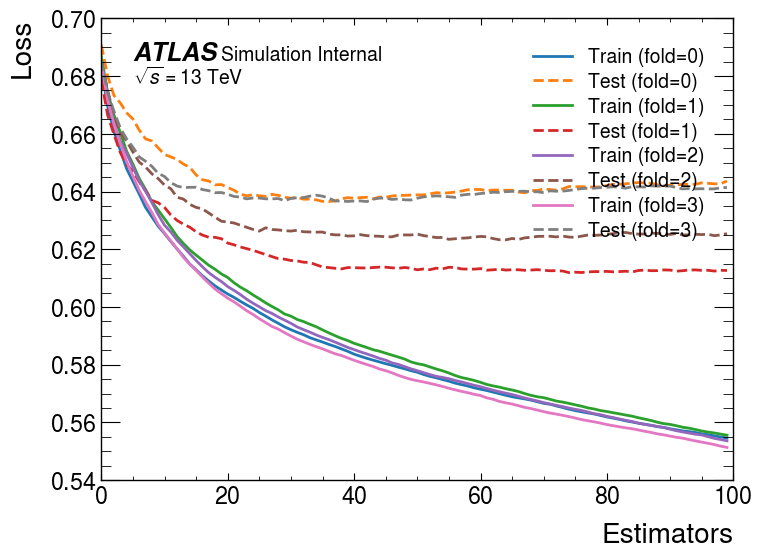

In [12]:
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [15]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.69844985, 0.5997103 , 0.76839554, ..., 0.8018644 , 0.82628655,
       0.74264383], dtype=float32), array([0.7288282 , 0.596118  , 0.73627937, ..., 0.7896769 , 0.7942964 ,
       0.6132207 ], dtype=float32), array([0.7562175 , 0.63562447, 0.7812595 , ..., 0.8348161 , 0.79913634,
       0.67131126], dtype=float32), array([0.6843941 , 0.64700854, 0.68538624, ..., 0.69455284, 0.83205986,
       0.728224  ], dtype=float32)]
Bkg:  [array([0.45193344, 0.6431001 , 0.7982446 , ..., 0.6613753 , 0.274555  ,
       0.7440531 ], dtype=float32), array([0.39147604, 0.66971177, 0.84973216, ..., 0.1390226 , 0.41110387,
       0.80214834], dtype=float32), array([0.4915794 , 0.70894516, 0.7654606 , ..., 0.12677047, 0.34067836,
       0.6861383 ], dtype=float32), array([0.37171933, 0.63014203, 0.72463936, ..., 0.1402112 , 0.5178295 ,
       0.7255807 ], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3959


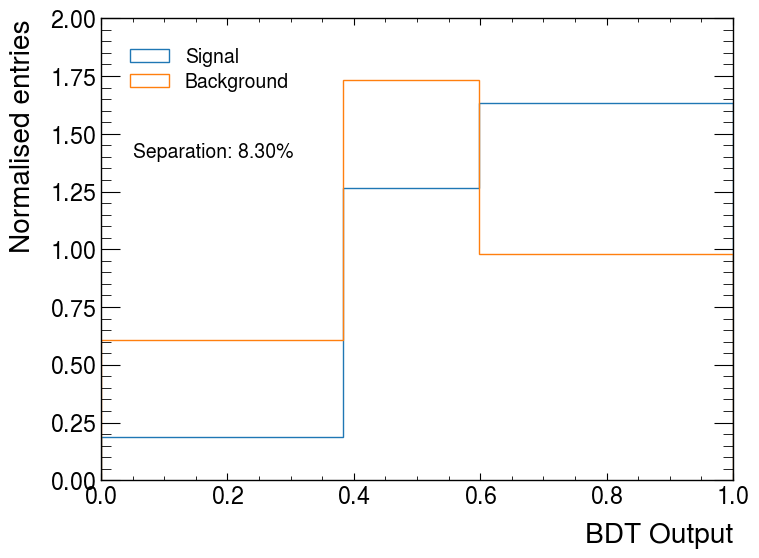

In [16]:
# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.4, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.png')
plt.legend()

# 2. Scaling absolute to nominal - all backgrounds - reducing #estimators from 100 to 50

In [26]:

# Doing it by scaling (all) the background weights from absolute to nominal normalisation and then using them in training

n_estimators = 50
# Current model with no reweighting
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]

    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    # normalisation for tty prod
    
    # Background 1: Apply condition for positive weights and normalization factor
    bkgttyprod_train_mask = (df_bkg_ttyprod['eventNumber'] % nfolds != fold) #& (df_bkg_ttyprod['weight'] > 0)
    bkgttyprod_test_mask = (df_bkg_ttyprod['eventNumber'] % nfolds == fold) #& (df_bkg_ttyprod['weight'] > 0)

    # Select train and test sets for bkg1
    X_bkg1_train = df_bkg_ttyprod[feature_cols][bkgttyprod_train_mask]
    w_bkg1_train = df_bkg_ttyprod['weight'][bkgttyprod_train_mask]
    
    X_bkg1_test = df_bkg_ttyprod[feature_cols][bkgttyprod_test_mask]
    w_bkg1_test = df_bkg_ttyprod['weight'][bkgttyprod_test_mask]

    
    # Nominal background weight sums
    total_bkg_ttyprod_weight_nominal_train = np.sum(w_bkg1_train)
    total_bkg_ttyprod_weight_nominal_test = np.sum(w_bkg1_test)

    # Absolute background weights
    w_bkg_ttyprod_train_abs = np.abs(w_bkg1_train)
    w_bkg_ttyprod_test_abs = np.abs(w_bkg1_test)

    # Sum of absolute weights for background
    total_bkg_weight_abs_train = np.sum(w_bkg_ttyprod_train_abs)
    total_bkg_weight_abs_test = np.sum(w_bkg_ttyprod_test_abs)

    # Normalization factors for background weights
    norm_factor_bkg_train = total_bkg_ttyprod_weight_nominal_train / total_bkg_weight_abs_train 
    norm_factor_bkg_test = total_bkg_ttyprod_weight_nominal_test / total_bkg_weight_abs_test
    
    print('Normalisation factors (train, test): ',norm_factor_bkg_train, norm_factor_bkg_test ) # Normalisation factors (train, test): around 0.40 0.40 
    
    # Scale background weights to maintain nominal background normalization by multiplying with nom/abs scale
    w_bkg_train_scaled_ttyprod = w_bkg_ttyprod_train_abs * norm_factor_bkg_train
    w_bkg_test_scaled_ttyprod = w_bkg_ttyprod_test_abs * norm_factor_bkg_test
    
    #---------------------  

 


    # normalisation for tty dec

    
    X_bkg2_train = df_bkg_ttydec[feature_cols][df_bkg_ttydec['eventNumber']%nfolds != fold]
    w_bkg2_train = df_bkg_ttydec['weight'][df_bkg_ttydec['eventNumber']%nfolds != fold]

    X_bkg2_test = df_bkg_ttydec[feature_cols][df_bkg_ttydec['eventNumber']%nfolds == fold]
    w_bkg2_test = df_bkg_ttydec['weight'][df_bkg_ttydec['eventNumber']%nfolds == fold]   

   
    # Nominal background weight sums
    total_bkg_ttydec_weight_nominal_train = np.sum(w_bkg2_train)
    total_bkg_ttydec_weight_nominal_test = np.sum(w_bkg2_test)

    # Absolute background weights
    w_bkg_ttydec_train_abs = np.abs(w_bkg2_train)
    w_bkg_ttydec_test_abs = np.abs(w_bkg2_test)

    # Sum of absolute weights for background
    total_bkg_weight_abs_train = np.sum(w_bkg_ttydec_train_abs)
    total_bkg_weight_abs_test = np.sum(w_bkg_ttydec_test_abs)

    # Normalization factors for background weights
    norm_factor_bkg_train = total_bkg_ttydec_weight_nominal_train / total_bkg_weight_abs_train 
    norm_factor_bkg_test = total_bkg_ttydec_weight_nominal_test / total_bkg_weight_abs_test
    
    print('Normalisation factors (train, test): ',norm_factor_bkg_train, norm_factor_bkg_test ) # Normalisation factors (train, test): around 0.40 0.40 
    
    # Scale background weights to maintain nominal background normalization by multiplying with nom/abs scale
    w_bkg_train_scaled_ttydec = w_bkg_ttydec_train_abs * norm_factor_bkg_train
    w_bkg_test_scaled_ttydec = w_bkg_ttydec_test_abs * norm_factor_bkg_test
    
    #---------------------  

    
     # normalisation for tty dec

    
        
    X_bkg3_train = df_bkg_Vyy[feature_cols][df_bkg_Vyy['eventNumber']%nfolds != fold]
    w_bkg3_train = df_bkg_Vyy['weight'][df_bkg_Vyy['eventNumber']%nfolds != fold]

    X_bkg3_test = df_bkg_Vyy[feature_cols][df_bkg_Vyy['eventNumber']%nfolds == fold]
    w_bkg3_test = df_bkg_Vyy['weight'][df_bkg_Vyy['eventNumber']%nfolds == fold]   
   
    # Nominal background weight sums
    total_bkg_Vyy_weight_nominal_train = np.sum(w_bkg3_train)
    total_bkg_Vyy_weight_nominal_test = np.sum(w_bkg3_test)

    # Absolute background weights
    w_bkg_Vyy_train_abs = np.abs(w_bkg3_train)
    w_bkg_Vyy_test_abs = np.abs(w_bkg3_test)

    # Sum of absolute weights for background
    total_bkg_weight_abs_train = np.sum(w_bkg_Vyy_train_abs)
    total_bkg_weight_abs_test = np.sum(w_bkg_Vyy_test_abs)

    # Normalization factors for background weights
    norm_factor_bkg_train = total_bkg_Vyy_weight_nominal_train / total_bkg_weight_abs_train 
    norm_factor_bkg_test = total_bkg_Vyy_weight_nominal_test / total_bkg_weight_abs_test
    
    print('Normalisation factors (train, test): ',norm_factor_bkg_train, norm_factor_bkg_test ) # Normalisation factors (train, test): around 0.40 0.40 
    
    # Scale background weights to maintain nominal background normalization by multiplying with nom/abs scale
    w_bkg_train_scaled_Vyy = w_bkg_Vyy_train_abs * norm_factor_bkg_train
    w_bkg_test_scaled_Vyy = w_bkg_Vyy_test_abs * norm_factor_bkg_test
    


    #---------------------  

    
    X_bkg_train = np.concatenate([X_bkg1_train, X_bkg2_train, X_bkg3_train])
    w_bkg_train = np.concatenate([w_bkg_train_scaled_ttyprod, w_bkg_train_scaled_ttydec, w_bkg_train_scaled_Vyy])

    X_bkg_test = np.concatenate([X_bkg1_test, X_bkg2_test, X_bkg3_test])
    w_bkg_test = np.concatenate([w_bkg_test_scaled_ttyprod, w_bkg_test_scaled_ttydec, w_bkg_test_scaled_Vyy])  


    #print("Signal train values:", X_sig_train[0:1])

    #no need --> print('Weighting factors: ',w_bkg_train_scaled, w_bkg_test_scaled)

    # Combine signal and background data
    y_train = np.concatenate([np.ones_like(w_sig_train), np.zeros_like(w_bkg_train)])
    X_train = np.concatenate([X_sig_train, X_bkg_train])
    w_train = np.concatenate([w_sig_train, w_bkg_train])

    y_test = np.concatenate([np.ones_like(w_sig_test), np.zeros_like(w_bkg_test)])
    X_test = np.concatenate([X_sig_test, X_bkg_test])
    w_test = np.concatenate([w_sig_test, w_bkg_test])
    
    print("Lengths of train and test sets:")
    #print("Signal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    #print("Background train test(events,weights): ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    #print("prediction train test: ", len(y_train), len(y_test))
    #print("prediction values: ", y_train[-100:], y_test[-100:])
    #print("concatenated train test: ", len(X_train), len(X_test))
    #print("concatenated train test values: ", X_train[0:2], X_test[0:2])

    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    



Normalisation factors (train, test):  0.41093063 0.43087274
Normalisation factors (train, test):  1.0 1.0
Normalisation factors (train, test):  0.9936825 0.99049246
Lengths of train and test sets:
Train scores 0: [0.7010294258279147]
Test scores 0:  [0.635684774849314]
50
Normalisation factors (train, test):  0.42383444 0.39037722
Normalisation factors (train, test):  1.0 1.0
Normalisation factors (train, test):  0.9935061 0.98836654
Lengths of train and test sets:
Train scores 1: [0.7010294258279147, 0.7010225849248254]
Test scores 1:  [0.635684774849314, 0.6711062305927479]
50
Normalisation factors (train, test):  0.40133518 0.45853078
Normalisation factors (train, test):  1.0 1.0
Normalisation factors (train, test):  0.9925504 0.99242556
Lengths of train and test sets:
Train scores 2: [0.7010294258279147, 0.7010225849248254, 0.7045589764049739]
Test scores 2:  [0.635684774849314, 0.6711062305927479, 0.6442779088887248]
50
Normalisation factors (train, test):  0.42713702 0.38402638
N

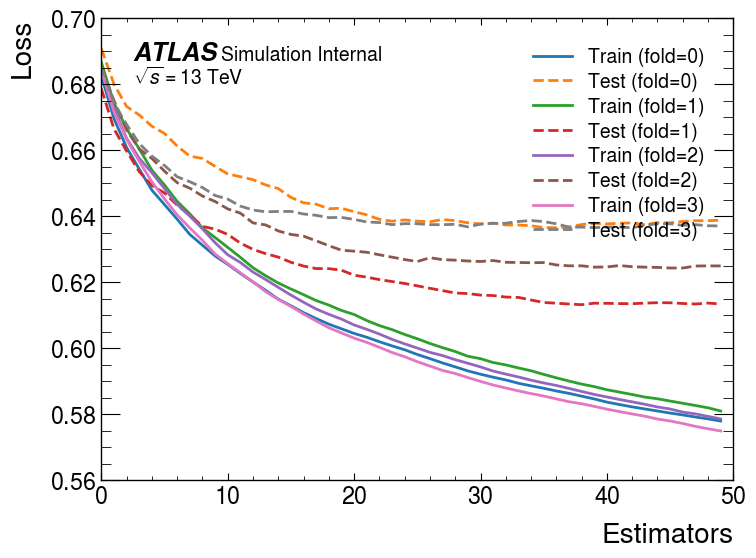

In [27]:
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [28]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.6376234 , 0.55956864, 0.7243972 , ..., 0.7647153 , 0.75564766,
       0.7480983 ], dtype=float32), array([0.675326 , 0.5520359, 0.7228626, ..., 0.7754578, 0.7373936,
       0.6453114], dtype=float32), array([0.7293247 , 0.60511017, 0.7419906 , ..., 0.8283237 , 0.77847177,
       0.69877446], dtype=float32), array([0.6481731 , 0.65009505, 0.6486239 , ..., 0.71454805, 0.8005662 ,
       0.72351635], dtype=float32)]
Bkg:  [array([0.43407288, 0.66205806, 0.8020048 , ..., 0.6247807 , 0.302284  ,
       0.7593259 ], dtype=float32), array([0.38915455, 0.6641595 , 0.84241587, ..., 0.2311897 , 0.47744378,
       0.79372716], dtype=float32), array([0.43035355, 0.67203736, 0.78755075, ..., 0.19434334, 0.42762   ,
       0.6908659 ], dtype=float32), array([0.34651285, 0.6560586 , 0.733353  , ..., 0.21789248, 0.4895268 ,
       0.7319877 ], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3959


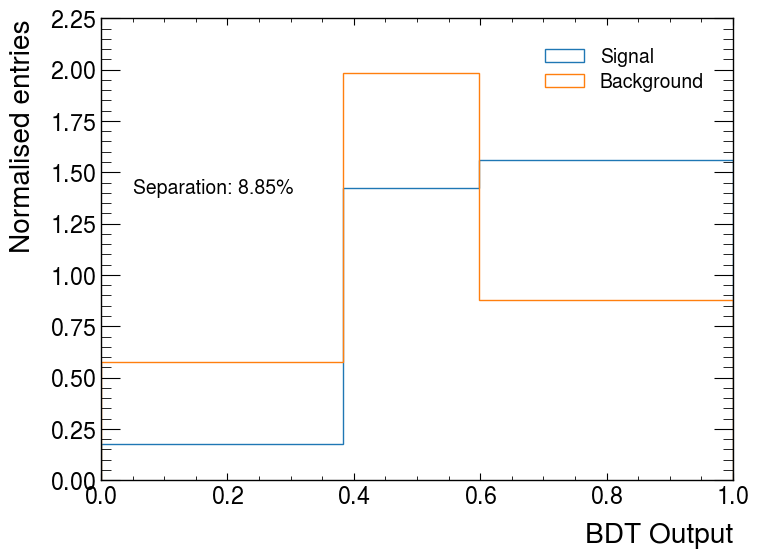

In [29]:
# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.4, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.png')
plt.legend()

In [17]:
# Changing number of estimators
# Doing it by scaling (all) the background weights from absolute to nominal normalisation and then using them in training

n_estimators = 60
# Current model with no reweighting
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]

    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    # normalisation for tty prod
    
    # Background 1: Apply condition for positive weights and normalization factor
    bkgttyprod_train_mask = (df_bkg_ttyprod['eventNumber'] % nfolds != fold) #& (df_bkg_ttyprod['weight'] > 0)
    bkgttyprod_test_mask = (df_bkg_ttyprod['eventNumber'] % nfolds == fold) #& (df_bkg_ttyprod['weight'] > 0)

    # Select train and test sets for bkg1
    X_bkg1_train = df_bkg_ttyprod[feature_cols][bkgttyprod_train_mask]
    w_bkg1_train = df_bkg_ttyprod['weight'][bkgttyprod_train_mask]
    
    X_bkg1_test = df_bkg_ttyprod[feature_cols][bkgttyprod_test_mask]
    w_bkg1_test = df_bkg_ttyprod['weight'][bkgttyprod_test_mask]

    
    # Nominal background weight sums
    total_bkg_ttyprod_weight_nominal_train = np.sum(w_bkg1_train)
    total_bkg_ttyprod_weight_nominal_test = np.sum(w_bkg1_test)

    # Absolute background weights
    w_bkg_ttyprod_train_abs = np.abs(w_bkg1_train)
    w_bkg_ttyprod_test_abs = np.abs(w_bkg1_test)

    # Sum of absolute weights for background
    total_bkg_weight_abs_train = np.sum(w_bkg_ttyprod_train_abs)
    total_bkg_weight_abs_test = np.sum(w_bkg_ttyprod_test_abs)

    # Normalization factors for background weights
    norm_factor_bkg_train = total_bkg_ttyprod_weight_nominal_train / total_bkg_weight_abs_train 
    norm_factor_bkg_test = total_bkg_ttyprod_weight_nominal_test / total_bkg_weight_abs_test
    
    print('Normalisation factors (train, test): ',norm_factor_bkg_train, norm_factor_bkg_test ) # Normalisation factors (train, test): around 0.40 0.40 
    
    # Scale background weights to maintain nominal background normalization by multiplying with nom/abs scale
    w_bkg_train_scaled_ttyprod = w_bkg_ttyprod_train_abs * norm_factor_bkg_train
    w_bkg_test_scaled_ttyprod = w_bkg_ttyprod_test_abs * norm_factor_bkg_test
    
    #---------------------  

 


    # normalisation for tty dec

    
    X_bkg2_train = df_bkg_ttydec[feature_cols][df_bkg_ttydec['eventNumber']%nfolds != fold]
    w_bkg2_train = df_bkg_ttydec['weight'][df_bkg_ttydec['eventNumber']%nfolds != fold]

    X_bkg2_test = df_bkg_ttydec[feature_cols][df_bkg_ttydec['eventNumber']%nfolds == fold]
    w_bkg2_test = df_bkg_ttydec['weight'][df_bkg_ttydec['eventNumber']%nfolds == fold]   

   
    # Nominal background weight sums
    total_bkg_ttydec_weight_nominal_train = np.sum(w_bkg2_train)
    total_bkg_ttydec_weight_nominal_test = np.sum(w_bkg2_test)

    # Absolute background weights
    w_bkg_ttydec_train_abs = np.abs(w_bkg2_train)
    w_bkg_ttydec_test_abs = np.abs(w_bkg2_test)

    # Sum of absolute weights for background
    total_bkg_weight_abs_train = np.sum(w_bkg_ttydec_train_abs)
    total_bkg_weight_abs_test = np.sum(w_bkg_ttydec_test_abs)

    # Normalization factors for background weights
    norm_factor_bkg_train = total_bkg_ttydec_weight_nominal_train / total_bkg_weight_abs_train 
    norm_factor_bkg_test = total_bkg_ttydec_weight_nominal_test / total_bkg_weight_abs_test
    
    print('Normalisation factors (train, test): ',norm_factor_bkg_train, norm_factor_bkg_test ) # Normalisation factors (train, test): around 0.40 0.40 
    
    # Scale background weights to maintain nominal background normalization by multiplying with nom/abs scale
    w_bkg_train_scaled_ttydec = w_bkg_ttydec_train_abs * norm_factor_bkg_train
    w_bkg_test_scaled_ttydec = w_bkg_ttydec_test_abs * norm_factor_bkg_test
    
    #---------------------  

    
     # normalisation for tty dec

    
        
    X_bkg3_train = df_bkg_Vyy[feature_cols][df_bkg_Vyy['eventNumber']%nfolds != fold]
    w_bkg3_train = df_bkg_Vyy['weight'][df_bkg_Vyy['eventNumber']%nfolds != fold]

    X_bkg3_test = df_bkg_Vyy[feature_cols][df_bkg_Vyy['eventNumber']%nfolds == fold]
    w_bkg3_test = df_bkg_Vyy['weight'][df_bkg_Vyy['eventNumber']%nfolds == fold]   
   
    # Nominal background weight sums
    total_bkg_Vyy_weight_nominal_train = np.sum(w_bkg3_train)
    total_bkg_Vyy_weight_nominal_test = np.sum(w_bkg3_test)

    # Absolute background weights
    w_bkg_Vyy_train_abs = np.abs(w_bkg3_train)
    w_bkg_Vyy_test_abs = np.abs(w_bkg3_test)

    # Sum of absolute weights for background
    total_bkg_weight_abs_train = np.sum(w_bkg_Vyy_train_abs)
    total_bkg_weight_abs_test = np.sum(w_bkg_Vyy_test_abs)

    # Normalization factors for background weights
    norm_factor_bkg_train = total_bkg_Vyy_weight_nominal_train / total_bkg_weight_abs_train 
    norm_factor_bkg_test = total_bkg_Vyy_weight_nominal_test / total_bkg_weight_abs_test
    
    print('Normalisation factors (train, test): ',norm_factor_bkg_train, norm_factor_bkg_test ) # Normalisation factors (train, test): around 0.40 0.40 
    
    # Scale background weights to maintain nominal background normalization by multiplying with nom/abs scale
    w_bkg_train_scaled_Vyy = w_bkg_Vyy_train_abs * norm_factor_bkg_train
    w_bkg_test_scaled_Vyy = w_bkg_Vyy_test_abs * norm_factor_bkg_test
    


    #---------------------  

    
    X_bkg_train = np.concatenate([X_bkg1_train, X_bkg2_train, X_bkg3_train])
    w_bkg_train = np.concatenate([w_bkg_train_scaled_ttyprod, w_bkg_train_scaled_ttydec, w_bkg_train_scaled_Vyy])

    X_bkg_test = np.concatenate([X_bkg1_test, X_bkg2_test, X_bkg3_test])
    w_bkg_test = np.concatenate([w_bkg_test_scaled_ttyprod, w_bkg_test_scaled_ttydec, w_bkg_test_scaled_Vyy])  


    #print("Signal train values:", X_sig_train[0:1])

    #no need --> print('Weighting factors: ',w_bkg_train_scaled, w_bkg_test_scaled)

    # Combine signal and background data
    y_train = np.concatenate([np.ones_like(w_sig_train), np.zeros_like(w_bkg_train)])
    X_train = np.concatenate([X_sig_train, X_bkg_train])
    w_train = np.concatenate([w_sig_train, w_bkg_train])

    y_test = np.concatenate([np.ones_like(w_sig_test), np.zeros_like(w_bkg_test)])
    X_test = np.concatenate([X_sig_test, X_bkg_test])
    w_test = np.concatenate([w_sig_test, w_bkg_test])
    
    print("Lengths of train and test sets:")
    #print("Signal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    #print("Background train test(events,weights): ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    #print("prediction train test: ", len(y_train), len(y_test))
    #print("prediction values: ", y_train[-100:], y_test[-100:])
    #print("concatenated train test: ", len(X_train), len(X_test))
    #print("concatenated train test values: ", X_train[0:2], X_test[0:2])

    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    



Normalisation factors (train, test):  0.41093063 0.43087274
Normalisation factors (train, test):  1.0 1.0
Normalisation factors (train, test):  0.9936825 0.99049246
Lengths of train and test sets:
Train scores 0: [0.7060066304377595]
Test scores 0:  [0.6405437773880776]
60
Normalisation factors (train, test):  0.42383444 0.39037722
Normalisation factors (train, test):  1.0 1.0
Normalisation factors (train, test):  0.9935061 0.98836654
Lengths of train and test sets:
Train scores 1: [0.7060066304377595, 0.7056276575504415]
Test scores 1:  [0.6405437773880776, 0.6723151651686732]
60
Normalisation factors (train, test):  0.40133518 0.45853078
Normalisation factors (train, test):  1.0 1.0
Normalisation factors (train, test):  0.9925504 0.99242556
Lengths of train and test sets:
Train scores 2: [0.7060066304377595, 0.7056276575504415, 0.7105158190779411]
Test scores 2:  [0.6405437773880776, 0.6723151651686732, 0.6434578339611878]
60
Normalisation factors (train, test):  0.42713702 0.3840263

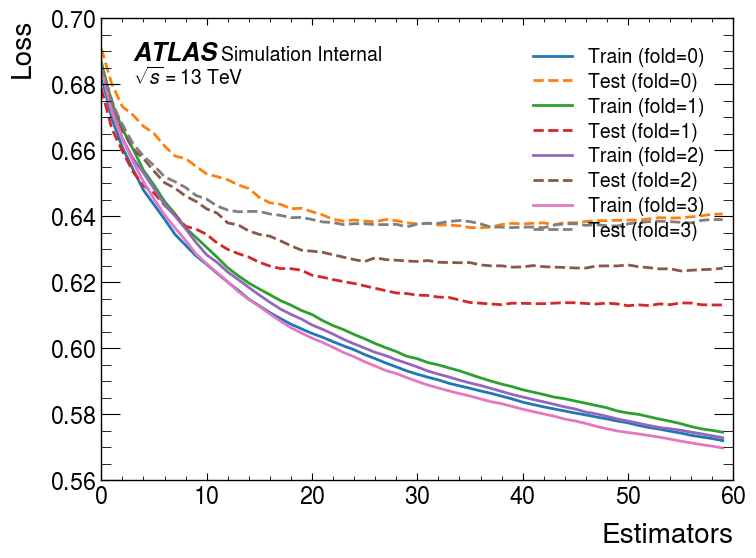

In [18]:
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [19]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.66714406, 0.6003648 , 0.72741836, ..., 0.77729845, 0.76971173,
       0.73640126], dtype=float32), array([0.703212 , 0.5646057, 0.701289 , ..., 0.7821711, 0.7438296,
       0.6652787], dtype=float32), array([0.7456227 , 0.6219083 , 0.7428252 , ..., 0.81727993, 0.77046406,
       0.6963042 ], dtype=float32), array([0.66798776, 0.6601335 , 0.6558398 , ..., 0.7152098 , 0.7989531 ,
       0.7181265 ], dtype=float32)]
Bkg:  [array([0.43879366, 0.6637818 , 0.7894193 , ..., 0.6505835 , 0.31493765,
       0.7546978 ], dtype=float32), array([0.3769805 , 0.66190463, 0.8394713 , ..., 0.19616605, 0.4378548 ,
       0.8148409 ], dtype=float32), array([0.44522494, 0.67201585, 0.800368  , ..., 0.17111951, 0.38905436,
       0.6939471 ], dtype=float32), array([0.3337791 , 0.6560488 , 0.73899925, ..., 0.20288025, 0.50209963,
       0.74061066], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3959


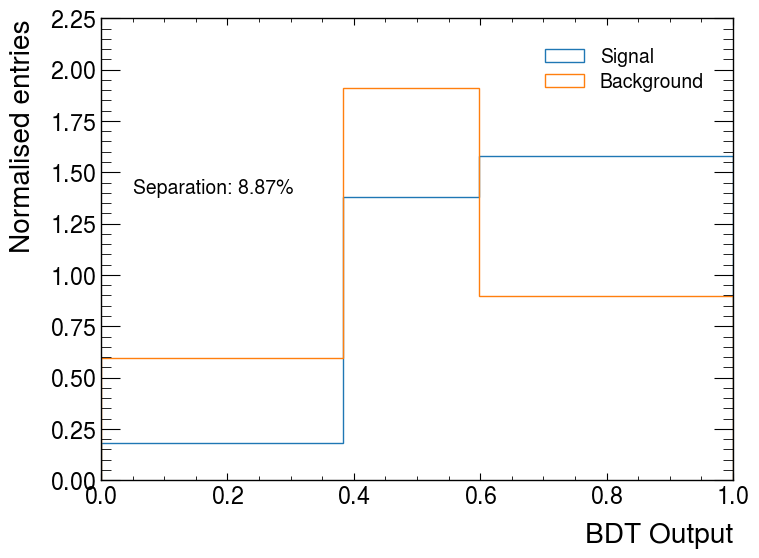

In [20]:
# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.4, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.png')
plt.legend()

# 3. Scaling positive only weights to nominal norm- tty prod only

In [103]:


# Doing it by scaling the "positive" background weights from their positive to nominal normalisation and then using them in training

n_estimators = 100
# Current model with no reweighting
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]

    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    
    # Background 1: Apply condition for positive weights and normalization factor
    bkgttyprod_pos_train_mask = (df_bkg_ttyprod['eventNumber'] % nfolds != fold) & (df_bkg_ttyprod['weight'] > 0)
    bkgttyprod_pos_test_mask = (df_bkg_ttyprod['eventNumber'] % nfolds == fold) & (df_bkg_ttyprod['weight'] > 0)

    bkgttyprod_train_mask = (df_bkg_ttyprod['eventNumber'] % nfolds != fold) #& (df_bkg_ttyprod['weight'] > 0)
    bkgttyprod_test_mask = (df_bkg_ttyprod['eventNumber'] % nfolds == fold) #& (df_bkg_ttyprod['weight'] > 0)
    
    # Select train and test positive sets for bkg1
    X_bkg1_pos_train = df_bkg_ttyprod[feature_cols][bkgttyprod_pos_train_mask]
    w_bkg1_pos_train = df_bkg_ttyprod['weight'][bkgttyprod_pos_train_mask]
    
    X_bkg1_pos_test = df_bkg_ttyprod[feature_cols][bkgttyprod_pos_test_mask]
    w_bkg1_pos_test = df_bkg_ttyprod['weight'][bkgttyprod_pos_test_mask]

    # Select train and test sets for bkg1
    X_bkg1_train = df_bkg_ttyprod[feature_cols][bkgttyprod_train_mask]
    w_bkg1_train = df_bkg_ttyprod['weight'][bkgttyprod_train_mask]
    
    X_bkg1_test = df_bkg_ttyprod[feature_cols][bkgttyprod_test_mask]
    w_bkg1_test = df_bkg_ttyprod['weight'][bkgttyprod_test_mask]

    
    # Nominal background weight sums
    total_bkg_ttyprod_weight_nominal_train = np.sum(w_bkg1_train)
    total_bkg_ttyprod_weight_nominal_test = np.sum(w_bkg1_test)


    # Sum of absolute weights for background
    total_bkg_weight_pos_train = np.sum(w_bkg1_pos_train)
    total_bkg_weight_pos_test = np.sum(w_bkg1_pos_test)

    # Normalization factors for background weights
    norm_factor_bkg_train = total_bkg_ttyprod_weight_nominal_train / total_bkg_weight_pos_train 
    norm_factor_bkg_test = total_bkg_ttyprod_weight_nominal_test / total_bkg_weight_pos_test
    
    print('Normalisation factors (train, test): ',norm_factor_bkg_train, norm_factor_bkg_test ) # Normalisation factors (train, test): around 0.58 0.58 which is nominal 16 events(nominal number)/ positive weights only (27.4 or so) 
    
    # Scale background weights to maintain nominal background normalization by multiplying with nom/abs scale
    w_bkg_train_scaled = w_bkg1_train * norm_factor_bkg_train
    w_bkg_test_scaled = w_bkg1_test * norm_factor_bkg_test
    
 


    print('Scaling changes:')
    print('List w_bkg1_train:', w_bkg1_train[0:3])
    print('List w_bkg1_train after scaling:', w_bkg_train_scaled[0:3])
    
    print("Background train test positive only (events,weights): ", len(X_bkg1_train), len(X_bkg1_test))


    X_bkg2_train = df_bkg_ttydec[feature_cols][df_bkg_ttydec['eventNumber']%nfolds != fold]
    w_bkg2_train = df_bkg_ttydec['weight'][df_bkg_ttydec['eventNumber']%nfolds != fold]

    X_bkg2_test = df_bkg_ttydec[feature_cols][df_bkg_ttydec['eventNumber']%nfolds == fold]
    w_bkg2_test = df_bkg_ttydec['weight'][df_bkg_ttydec['eventNumber']%nfolds == fold]   

      
        
        
    X_bkg3_train = df_bkg_Vyy[feature_cols][df_bkg_Vyy['eventNumber']%nfolds != fold]
    w_bkg3_train = df_bkg_Vyy['weight'][df_bkg_Vyy['eventNumber']%nfolds != fold]

    X_bkg3_test = df_bkg_Vyy[feature_cols][df_bkg_Vyy['eventNumber']%nfolds == fold]
    w_bkg3_test = df_bkg_Vyy['weight'][df_bkg_Vyy['eventNumber']%nfolds == fold]   

    
    
    
    X_bkg_train = np.concatenate([X_bkg1_train, X_bkg2_train, X_bkg3_train])
    w_bkg_train = np.concatenate([w_bkg_train_scaled, w_bkg2_train, w_bkg3_train])

    X_bkg_test = np.concatenate([X_bkg1_test, X_bkg2_test, X_bkg3_test])
    w_bkg_test = np.concatenate([w_bkg_test_scaled, w_bkg2_test, w_bkg3_test])  


    print("Signal train values:", X_sig_train[0:1])

    #no need --> print('Weighting factors: ',w_bkg_train_scaled, w_bkg_test_scaled)

    # Combine signal and background data
    y_train = np.concatenate([np.ones_like(w_sig_train), np.zeros_like(w_bkg_train)])
    X_train = np.concatenate([X_sig_train, X_bkg_train])
    w_train = np.concatenate([w_sig_train, w_bkg_train])

    y_test = np.concatenate([np.ones_like(w_sig_test), np.zeros_like(w_bkg_test)])
    X_test = np.concatenate([X_sig_test, X_bkg_test])
    w_test = np.concatenate([w_sig_test, w_bkg_test])
    
    print("Lengths of train and test sets:")
    print("Signal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test(events,weights): ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    #print("prediction train test: ", len(y_train), len(y_test))
    #print("prediction values: ", y_train[-100:], y_test[-100:])
    #print("concatenated train test: ", len(X_train), len(X_test))
    #print("concatenated train test values: ", X_train[0:2], X_test[0:2])

    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    





Normalisation factors (train, test):  0.5824959 0.60225165
Scaling changes:
List w_bkg1_train: entry
0   -0.026033
3    0.023529
5    0.018663
Name: weight, dtype: float32
List w_bkg1_train after scaling: entry
0   -0.015164
3    0.013706
5    0.010871
Name: weight, dtype: float32
Signal train values:         jet_pt[:,0]   jet_pt[:,1]       met_met  ph_eta[:,0]  ph_eta[:,1]  \
entry                                                                       
0      150484.40625  73511.679688  94067.289062    -0.810186    -2.244604   

         ph_pt[:,0]    ph_pt[:,1]  ph_mlph_closest[:,0]  ph_mlph_closest[:,1]  \
entry                                                                           
0      69320.984375  40159.082031           111921.4375          85738.242188   

             diph_M  event_nbjets70  dr_lep_ph0  dr_lep_ph1  \
entry                                                         
0      133776.86572               1    1.696234    2.024914   

       ph_conversion_type[:,1] 

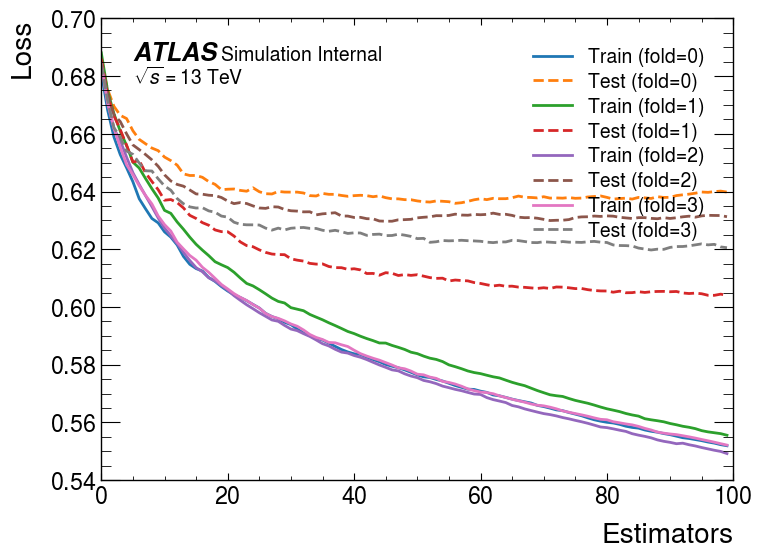

In [104]:
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [105]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.6821435 , 0.6754499 , 0.78113145, ..., 0.787081  , 0.81128496,
       0.694548  ], dtype=float32), array([0.6531261 , 0.6690159 , 0.7841527 , ..., 0.83797604, 0.78095406,
       0.58472246], dtype=float32), array([0.66832006, 0.6486638 , 0.7904681 , ..., 0.8145088 , 0.81791323,
       0.67550397], dtype=float32), array([0.59053606, 0.66831654, 0.712348  , ..., 0.7634383 , 0.80930793,
       0.6839208 ], dtype=float32)]
Bkg:  [array([0.3802908 , 0.5999616 , 0.77094793, ..., 0.56903285, 0.2969111 ,
       0.69651186], dtype=float32), array([0.3458362 , 0.5433752 , 0.788837  , ..., 0.14726037, 0.42405343,
       0.8022717 ], dtype=float32), array([0.4501558 , 0.64751387, 0.75863177, ..., 0.15514879, 0.28992516,
       0.7079001 ], dtype=float32), array([0.41284016, 0.5947748 , 0.715664  , ..., 0.14654768, 0.5888778 ,
       0.7102969 ], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3959


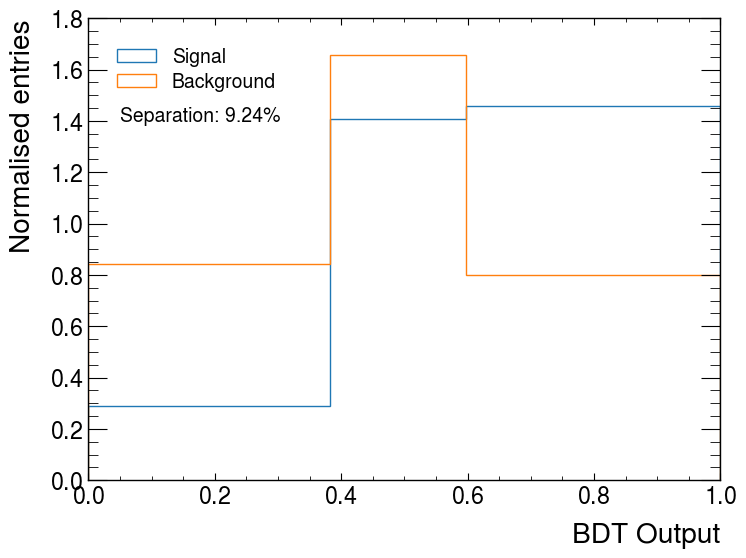

In [106]:
# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.4, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.png')
plt.legend()

# 3. Scaling positive only weights to nominal norm- all backgrounds

In [18]:

# Doing it by scaling (all) the "positive" background weights from their positive to nominal normalisation and then using them in training - for all samples

n_estimators = 100
# Current model with no reweighting
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):

    
    
        
    # Background 1: Apply condition for positive weights and normalization factor
    X_sig_pos_train_mask = (df_sig['eventNumber'] % nfolds != fold) & (df_sig['weight'] > 0)
    X_sig_pos_test_mask = (df_sig['eventNumber'] % nfolds == fold) & (df_sig['weight'] > 0)

    X_sig_train_mask = (df_sig['eventNumber'] % nfolds != fold) #& (df_bkg_ttyprod['weight'] > 0)
    X_sig_test_mask = (df_sig['eventNumber'] % nfolds == fold) #& (df_bkg_ttyprod['weight'] > 0)
    
    # Select train and test positive sets for bkg1
    X_sig_pos_train = df_sig[feature_cols][X_sig_pos_train_mask]
    w_sig_pos_train = df_sig['weight'][X_sig_pos_train_mask]
    
    X_sig_pos_test = df_sig[feature_cols][X_sig_pos_test_mask]
    w_sig_pos_test = df_sig['weight'][X_sig_pos_test_mask]

    # Select train and test sets for bkg1
    X_sig_train = df_sig[feature_cols][X_sig_train_mask]
    w_sig_train = df_sig['weight'][X_sig_train_mask]
    
    X_sig_test = df_sig[feature_cols][X_sig_test_mask]
    w_sig_test = df_sig['weight'][X_sig_test_mask]
    print("Background train test all only tty prod (events,weights): ", len(X_sig_train), len(X_sig_test))

    print("Background train test positive only tty prod (events,weights): ", len(X_sig_pos_train), len(X_sig_pos_test))

    """
    
    X_sig_pos_train_mask = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold] & (df_bkg_ttyprod['weight'] > 0)
    X_sig_pos_test_mask = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold] & (df_bkg_ttyprod['weight'] > 0)

    
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    #w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]

    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    #w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]  
    
    # Select train and test sets for bkg1
    X_sig_pos_train = df_sig[feature_cols][X_sig_pos_train_mask]
    w_sig_pos_train = df_sig['weight'][X_sig_pos_train_mask]

    # Select train and test sets for bkg1
    X_sig__train = df_sig[feature_cols][X_sig_pos_train_mask]
    w_sig__train = df_sig['weight'][X_sig_pos_train_mask]
    """
    
    # Background 1: Apply condition for positive weights and normalization factor
    bkgttyprod_pos_train_mask = (df_bkg_ttyprod['eventNumber'] % nfolds != fold) & (df_bkg_ttyprod['weight'] > 0)
    bkgttyprod_pos_test_mask = (df_bkg_ttyprod['eventNumber'] % nfolds == fold) & (df_bkg_ttyprod['weight'] > 0)

    bkgttyprod_train_mask = (df_bkg_ttyprod['eventNumber'] % nfolds != fold) #& (df_bkg_ttyprod['weight'] > 0)
    bkgttyprod_test_mask = (df_bkg_ttyprod['eventNumber'] % nfolds == fold) #& (df_bkg_ttyprod['weight'] > 0)
    
    # Select train and test positive sets for bkg1
    X_bkg1_pos_train = df_bkg_ttyprod[feature_cols][bkgttyprod_pos_train_mask]
    w_bkg1_pos_train = df_bkg_ttyprod['weight'][bkgttyprod_pos_train_mask]
    
    X_bkg1_pos_test = df_bkg_ttyprod[feature_cols][bkgttyprod_pos_test_mask]
    w_bkg1_pos_test = df_bkg_ttyprod['weight'][bkgttyprod_pos_test_mask]

    # Select train and test sets for bkg1
    X_bkg1_train = df_bkg_ttyprod[feature_cols][bkgttyprod_train_mask]
    w_bkg1_train = df_bkg_ttyprod['weight'][bkgttyprod_train_mask]
    
    X_bkg1_test = df_bkg_ttyprod[feature_cols][bkgttyprod_test_mask]
    w_bkg1_test = df_bkg_ttyprod['weight'][bkgttyprod_test_mask]
    print("Background train test all only tty prod (events,weights): ", len(X_bkg1_train), len(X_bkg1_test))

    print("Background train test positive only tty prod (events,weights): ", len(X_bkg1_pos_train), len(X_bkg1_pos_test))

    
    # Nominal background weight sums
    total_bkg_ttyprod_weight_nominal_train = np.sum(w_bkg1_train)
    total_bkg_ttyprod_weight_nominal_test = np.sum(w_bkg1_test)


    # Sum of absolute weights for background
    total_bkg_weight_pos_train = np.sum(w_bkg1_pos_train)
    total_bkg_weight_pos_test = np.sum(w_bkg1_pos_test)

    # Normalization factors for background weights
    norm_factor_bkg_train = total_bkg_ttyprod_weight_nominal_train / total_bkg_weight_pos_train 
    norm_factor_bkg_test = total_bkg_ttyprod_weight_nominal_test / total_bkg_weight_pos_test
    
    print('Normalisation factors (train, test): ',norm_factor_bkg_train, norm_factor_bkg_test ) # Normalisation factors (train, test): around 0.58 0.58 which is nominal 16 events(nominal number)/ positive weights only (27.4 or so) 
    
    # Scale background weights to maintain nominal background normalization by multiplying with nom/abs scale
    w_bkg_train_scaled_ttyprod = w_bkg1_train * norm_factor_bkg_train
    w_bkg_test_scaled_ttyprod = w_bkg1_test * norm_factor_bkg_test
    
 
    print('Scaling changes tty prod:')
    print('List w_bkg1_train:', w_bkg1_train[0:3])
    print('List w_bkg1_train after scaling:', w_bkg_train_scaled_ttyprod[0:3])

    #---------------------
    
    # normalisation for tty dec
    
    
    # Background 2: Apply condition for positive weights and normalization factor
    bkgttydec_pos_train_mask = (df_bkg_ttydec['eventNumber'] % nfolds != fold) & (df_bkg_ttydec['weight'] > 0)
    bkgttydec_pos_test_mask = (df_bkg_ttydec['eventNumber'] % nfolds == fold) & (df_bkg_ttydec['weight'] > 0)

    bkgttydec_train_mask = (df_bkg_ttydec['eventNumber'] % nfolds != fold) #& (df_bkg_ttyprod['weight'] > 0)
    bkgttydec_test_mask = (df_bkg_ttydec['eventNumber'] % nfolds == fold) #& (df_bkg_ttyprod['weight'] > 0)
    
    # Select train and test positive sets for bkg2
    X_bkg2_pos_train = df_bkg_ttydec[feature_cols][bkgttydec_pos_train_mask]
    w_bkg2_pos_train = df_bkg_ttydec['weight'][bkgttydec_pos_train_mask]
    
    X_bkg2_pos_test = df_bkg_ttydec[feature_cols][bkgttydec_pos_test_mask]
    w_bkg2_pos_test = df_bkg_ttydec['weight'][bkgttydec_pos_test_mask]

    # Select train and test sets for bkg2
    X_bkg2_train = df_bkg_ttydec[feature_cols][bkgttydec_train_mask]
    w_bkg2_train = df_bkg_ttydec['weight'][bkgttydec_train_mask]
    
    X_bkg2_test = df_bkg_ttydec[feature_cols][bkgttydec_test_mask]
    w_bkg2_test = df_bkg_ttydec['weight'][bkgttydec_test_mask]

    print("Background train test  only tty dec (events,weights): ", len(X_bkg2_train), len(X_bkg2_test))

    print("Background train test positive only tty dec (events,weights): ", len(X_bkg2_pos_train), len(X_bkg2_pos_test))

    # Nominal background weight sums
    total_bkg_ttydec_weight_nominal_train = np.sum(w_bkg2_train)
    total_bkg_ttydec_weight_nominal_test = np.sum(w_bkg2_test)


    # Sum of absolute weights for background
    total_bkg_weight_pos_train = np.sum(w_bkg2_pos_train)
    total_bkg_weight_pos_test = np.sum(w_bkg2_pos_test)

    # Normalization factors for background weights
    norm_factor_bkg_train = total_bkg_ttydec_weight_nominal_train / total_bkg_weight_pos_train 
    norm_factor_bkg_test = total_bkg_ttydec_weight_nominal_test / total_bkg_weight_pos_test
    
    print('Normalisation factors (train, test): ',norm_factor_bkg_train, norm_factor_bkg_test ) # Normalisation factors (train, test): around 0.58 0.58 which is nominal 16 events(nominal number)/ positive weights only (27.4 or so) 
    
    # Scale background weights to maintain nominal background normalization by multiplying with nom/abs scale
    w_bkg_train_scaled_ttydec = w_bkg2_train * norm_factor_bkg_train
    w_bkg_test_scaled_ttydec = w_bkg2_test * norm_factor_bkg_test
    
    print('Scaling changes tty dec:')
    print('List w_bkg2_train:', w_bkg2_train[0:3])
    print('List w_bkg2_train after scaling:', w_bkg_train_scaled_ttydec[0:3])
    
    #---------------------
    
    # normalisation for Vyy
          
    
    # Background 3: Apply condition for positive weights and normalization factor
    bkgVyy_pos_train_mask = (df_bkg_Vyy['eventNumber'] % nfolds != fold) & (df_bkg_Vyy['weight'] > 0)
    bkgVyy_pos_test_mask = (df_bkg_Vyy['eventNumber'] % nfolds == fold) & (df_bkg_Vyy['weight'] > 0)

    bkgVyy_train_mask = (df_bkg_Vyy['eventNumber'] % nfolds != fold) #& (df_bkg_ttyprod['weight'] > 0)
    bkgVyy_test_mask = (df_bkg_Vyy['eventNumber'] % nfolds == fold) #& (df_bkg_ttyprod['weight'] > 0)
    
    # Select train and test positive sets for bkg3
    X_bkg3_pos_train = df_bkg_Vyy[feature_cols][bkgVyy_pos_train_mask]
    w_bkg3_pos_train = df_bkg_Vyy['weight'][bkgVyy_pos_train_mask]
    
    X_bkg3_pos_test = df_bkg_Vyy[feature_cols][bkgVyy_pos_test_mask]
    w_bkg3_pos_test = df_bkg_Vyy['weight'][bkgVyy_pos_test_mask]

    # Select train and test sets for bkg3
    X_bkg3_train = df_bkg_Vyy[feature_cols][bkgVyy_train_mask]
    w_bkg3_train = df_bkg_Vyy['weight'][bkgVyy_train_mask]
    
    X_bkg3_test = df_bkg_Vyy[feature_cols][bkgVyy_test_mask]
    w_bkg3_test = df_bkg_Vyy['weight'][bkgVyy_test_mask]

    
    # Nominal background weight sums
    total_bkg_Vyy_weight_nominal_train = np.sum(w_bkg3_train)
    total_bkg_Vyy_weight_nominal_test = np.sum(w_bkg3_test)

    print("Background train test all weights only Vyy (events,weights): ", len(X_bkg3_train), len(X_bkg3_test))

    print("Background train test positive only Vyy (events,weights): ", len(X_bkg3_pos_train), len(X_bkg3_pos_test))

    # Sum of absolute weights for background
    total_bkg_weight_pos_train = np.sum(w_bkg3_pos_train)
    total_bkg_weight_pos_test = np.sum(w_bkg3_pos_test)

    # Normalization factors for background weights
    norm_factor_bkg_train = total_bkg_Vyy_weight_nominal_train / total_bkg_weight_pos_train 
    norm_factor_bkg_test = total_bkg_Vyy_weight_nominal_test / total_bkg_weight_pos_test
    
    print('Normalisation factors (train, test): ',norm_factor_bkg_train, norm_factor_bkg_test ) # Normalisation factors (train, test): around 0.58 0.58 which is nominal 16 events(nominal number)/ positive weights only (27.4 or so) 
    
    # Scale background weights to maintain nominal background normalization by multiplying with nom/abs scale
    w_bkg_train_scaled_Vyy = w_bkg3_train * norm_factor_bkg_train
    w_bkg_test_scaled_Vyy = w_bkg3_test * norm_factor_bkg_test
    
    print('Scaling changes tty dec:')
    print('List w_bkg3_train:', w_bkg3_train[0:3])
    print('List w_bkg3_train after scaling:', w_bkg_train_scaled_Vyy[0:3])
     

    
    # --------------------------
    
    X_bkg_train = np.concatenate([X_bkg1_train, X_bkg2_train, X_bkg3_train])
    w_bkg_train = np.concatenate([w_bkg_train_scaled_ttyprod, w_bkg_train_scaled_ttydec, w_bkg_train_scaled_Vyy])

    X_bkg_test = np.concatenate([X_bkg1_test, X_bkg2_test, X_bkg3_test])
    w_bkg_test = np.concatenate([w_bkg_test_scaled_ttyprod, w_bkg_test_scaled_ttydec, w_bkg_test_scaled_Vyy])  


    print("Signal train values:", X_sig_train[0:1])

    #no need --> print('Weighting factors: ',w_bkg_train_scaled, w_bkg_test_scaled)

    # Combine signal and background data
    y_train = np.concatenate([np.ones_like(w_sig_train), np.zeros_like(w_bkg_train)])
    X_train = np.concatenate([X_sig_train, X_bkg_train])
    w_train = np.concatenate([w_sig_train, w_bkg_train])

    y_test = np.concatenate([np.ones_like(w_sig_test), np.zeros_like(w_bkg_test)])
    X_test = np.concatenate([X_sig_test, X_bkg_test])
    w_test = np.concatenate([w_sig_test, w_bkg_test])
    
    print("Lengths of train and test sets:")
    print("Signal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test(events,weights): ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    #print("prediction train test: ", len(y_train), len(y_test))
    #print("prediction values: ", y_train[-100:], y_test[-100:])
    #print("concatenated train test: ", len(X_train), len(X_test))
    #print("concatenated train test values: ", X_train[0:2], X_test[0:2])

    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    





Background train test all only tty prod (events,weights):  243054 80846
Background train test positive only tty prod (events,weights):  242196 80552
Background train test all only tty prod (events,weights):  1469 482
Background train test positive only tty prod (events,weights):  1033 345
Normalisation factors (train, test):  0.5824959 0.60225165
Scaling changes tty prod:
List w_bkg1_train: entry
0   -0.026033
3    0.023529
5    0.018663
Name: weight, dtype: float32
List w_bkg1_train after scaling: entry
0   -0.015164
3    0.013706
5    0.010871
Name: weight, dtype: float32
Background train test  only tty dec (events,weights):  809 259
Background train test positive only tty dec (events,weights):  805 258
Normalisation factors (train, test):  1.0 1.0
Scaling changes tty dec:
List w_bkg2_train: entry
0    0.010566
1    0.007836
2    0.010096
Name: weight, dtype: float32
List w_bkg2_train after scaling: entry
0    0.010566
1    0.007836
2    0.010096
Name: weight, dtype: float32
Backgrou

Train scores 2: [0.724682208838461, 0.717804792689731, 0.7340077158301294]
Test scores 2:  [0.6286029793704447, 0.675891388237716, 0.6441376996224285]
100
Background train test all only tty prod (events,weights):  242836 81064
Background train test positive only tty prod (events,weights):  241977 80771
Background train test all only tty prod (events,weights):  1439 512
Background train test positive only tty prod (events,weights):  1026 352
Normalisation factors (train, test):  0.5985928 0.5549408
Scaling changes tty prod:
List w_bkg1_train: entry
0   -0.026033
1   -0.019855
2    0.017613
Name: weight, dtype: float32
List w_bkg1_train after scaling: entry
0   -0.015583
1   -0.011885
2    0.010543
Name: weight, dtype: float32
Background train test  only tty dec (events,weights):  783 285
Background train test positive only tty dec (events,weights):  780 283
Normalisation factors (train, test):  1.0 1.0000001
Scaling changes tty dec:
List w_bkg2_train: entry
0    0.010566
1    0.007836
2

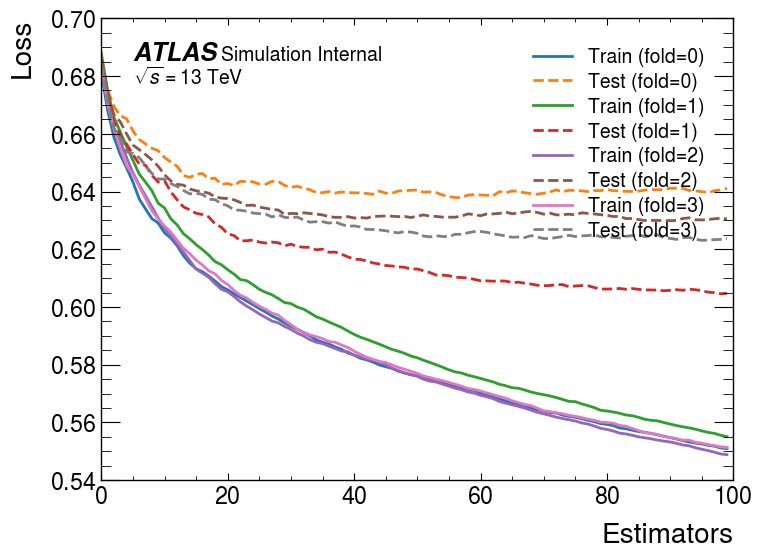

In [31]:
    
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [33]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.66024345, 0.6468772 , 0.75153923, ..., 0.7850099 , 0.7644426 ,
       0.69127816], dtype=float32), array([0.65040565, 0.62446636, 0.7500111 , ..., 0.8442172 , 0.7339883 ,
       0.63484615], dtype=float32), array([0.7030339 , 0.55441314, 0.7343395 , ..., 0.7832692 , 0.7873564 ,
       0.6560183 ], dtype=float32), array([0.4938426 , 0.63094497, 0.73463553, ..., 0.7312507 , 0.8314702 ,
       0.70779335], dtype=float32)]
Bkg:  [array([0.38251063, 0.5660898 , 0.7724799 , ..., 0.6189138 , 0.29773405,
       0.7168973 ], dtype=float32), array([0.34155354, 0.6330499 , 0.8148433 , ..., 0.13045304, 0.4590084 ,
       0.7679795 ], dtype=float32), array([0.53740585, 0.6567113 , 0.6938065 , ..., 0.13617018, 0.3059705 ,
       0.6508256 ], dtype=float32), array([0.3684127 , 0.5904951 , 0.7534532 , ..., 0.13460453, 0.5881461 ,
       0.6959099 ], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3959


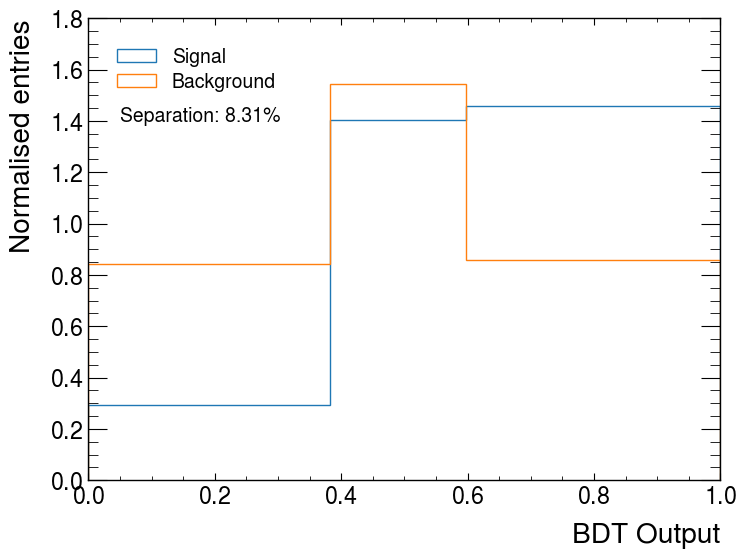

In [34]:
# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.4, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.png')
plt.legend()

In [33]:
# Current model with no reweighting - only for ttyy versus tty production
# SINGLE MODEL  : Using XGB Classifier
models_1on1 = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig_ttyy[feature_cols][df_sig_ttyy['eventNumber']%nfolds != fold]
    w_sig_train = df_sig_ttyy['weight'][df_sig_ttyy['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig_ttyy[feature_cols][df_sig_ttyy['eventNumber']%nfolds == fold]
    w_sig_test = df_sig_ttyy['weight'][df_sig_ttyy['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg_tty[feature_cols][df_bkg_tty['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg_tty['weight'][df_bkg_tty['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg_tty[feature_cols][df_bkg_tty['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg_tty['weight'][df_bkg_tty['eventNumber']%nfolds == fold]
    
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    print("Signal train values:", X_sig_train[0:1])
    
    print("Lengths of train and test sets:")
    print("Signal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test(events,weights): ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    print("prediction train test: ", len(y_train), len(y_test))
    print("prediction values: ", y_train[-100:], y_test[-100:])
    #print("concatenated train test: ", len(X_train), len(X_test))
    #print("concatenated train test values: ", X_train[0:2], X_test[0:2])

    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model_1on1 = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model_1on1.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models_1on1.append(model_1on1)
    scores_train.append(model_1on1.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model_1on1.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters_1on1 = len(models_1on1[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters_1on1)
    for i in range(n_boosters_1on1):
        ypred = models_1on1[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models_1on1[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

Signal train values:         jet_pt[:,0]   jet_pt[:,1]       met_met  ph_eta[:,0]  ph_eta[:,1]  \
entry                                                                       
0      150484.40625  73511.679688  94067.289062    -0.810186    -2.244604   

         ph_pt[:,0]    ph_pt[:,1]  ph_mlph_closest[:,0]  ph_mlph_closest[:,1]  \
entry                                                                           
0      69320.984375  40159.082031           111921.4375          85738.242188   

             diph_M  event_nbjets70  dr_lep_ph0  dr_lep_ph1  \
entry                                                         
0      133776.86572               1    1.696234    2.024914   

       ph_conversion_type[:,1]  ph_conversion_type[:,0]  \
entry                                                     
0                            0                        0   

       ph_mphb70_closest[:,0]  ph_mphb70_closest[:,1]   m_AllObjects  \
entry                                                          

Train scores 3: [0.7160219016155549, 0.7113870186122749, 0.7144268339011907, 0.7105639172571762]
Test scores 3:  [0.6433535745116777, 0.6676095646263479, 0.6456136727310257, 0.6837663877038924]
100


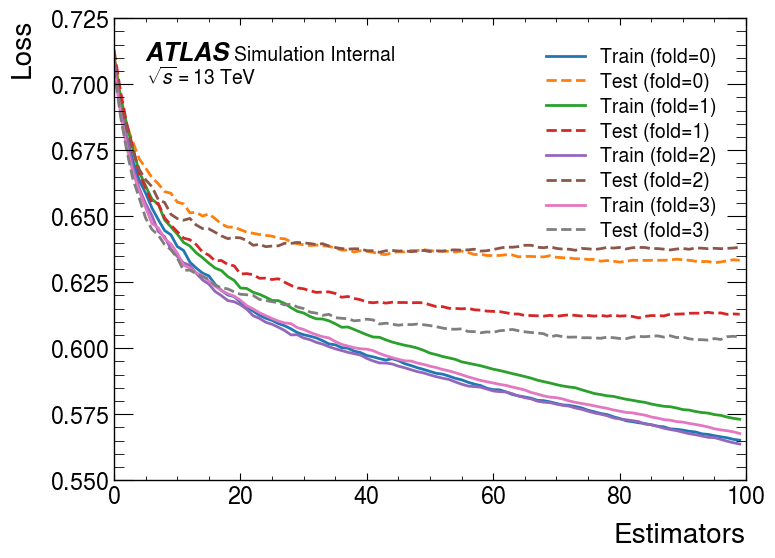

In [34]:
    
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [35]:
X_sig = df_sig_ttyy[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg_tty[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models_1on1]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models_1on1]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig_ttyy['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg_tty['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.59978974, 0.54093075, 0.8619098 , ..., 0.84129405, 0.76593864,
       0.7210707 ], dtype=float32), array([0.5688137 , 0.63653857, 0.8039945 , ..., 0.6768307 , 0.76256245,
       0.73997086], dtype=float32), array([0.50732905, 0.64780825, 0.8310685 , ..., 0.786034  , 0.7912087 ,
       0.85318846], dtype=float32), array([0.6339817 , 0.56487495, 0.74001825, ..., 0.7143521 , 0.755661  ,
       0.7314036 ], dtype=float32)]
Bkg:  [array([0.41797403, 0.47267678, 0.7137577 , ..., 0.27421564, 0.13408795,
       0.29316252], dtype=float32), array([0.43252861, 0.5106287 , 0.69937086, ..., 0.18418315, 0.17794544,
       0.34873322], dtype=float32), array([0.6456198 , 0.4574766 , 0.56979346, ..., 0.28250143, 0.102178  ,
       0.3081963 ], dtype=float32), array([0.4347638 , 0.6013311 , 0.71211314, ..., 0.22436449, 0.09015305,
       0.37739202], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3019


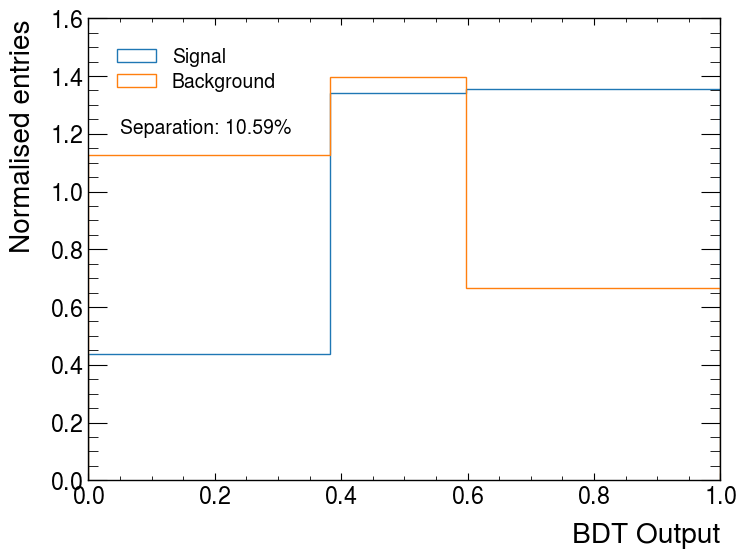

In [37]:
# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig_ttyy['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg_tty['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.2, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.png')
plt.legend()

In [38]:
# Current model with no reweighting - only for ttyy versus tty production with scale pos
# SINGLE MODEL  : Using XGB Classifier
models_1on1 = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig_ttyy[feature_cols][df_sig_ttyy['eventNumber']%nfolds != fold]
    w_sig_train = df_sig_ttyy['weight'][df_sig_ttyy['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig_ttyy[feature_cols][df_sig_ttyy['eventNumber']%nfolds == fold]
    w_sig_test = df_sig_ttyy['weight'][df_sig_ttyy['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg_tty[feature_cols][df_bkg_tty['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg_tty['weight'][df_bkg_tty['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg_tty[feature_cols][df_bkg_tty['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg_tty['weight'][df_bkg_tty['eventNumber']%nfolds == fold]
    
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    print("Signal train values:", X_sig_train[0:1])
    
    print("Lengths of train and test sets:")
    print("Signal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test(events,weights): ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    print("prediction train test: ", len(y_train), len(y_test))
    print("prediction values: ", y_train[-100:], y_test[-100:])
    #print("concatenated train test: ", len(X_train), len(X_test))
    #print("concatenated train test values: ", X_train[0:2], X_test[0:2])

    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model_1on1 = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators, scale_pos_weight=0.45)
    model_1on1.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models_1on1.append(model_1on1)
    scores_train.append(model_1on1.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model_1on1.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters_1on1 = len(models_1on1[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters_1on1)
    for i in range(n_boosters_1on1):
        ypred = models_1on1[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models_1on1[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

Signal train values:         jet_pt[:,0]   jet_pt[:,1]       met_met  ph_eta[:,0]  ph_eta[:,1]  \
entry                                                                       
0      150484.40625  73511.679688  94067.289062    -0.810186    -2.244604   

         ph_pt[:,0]    ph_pt[:,1]  ph_mlph_closest[:,0]  ph_mlph_closest[:,1]  \
entry                                                                           
0      69320.984375  40159.082031           111921.4375          85738.242188   

             diph_M  event_nbjets70  dr_lep_ph0  dr_lep_ph1  \
entry                                                         
0      133776.86572               1    1.696234    2.024914   

       ph_conversion_type[:,1]  ph_conversion_type[:,0]  \
entry                                                     
0                            0                        0   

       ph_mphb70_closest[:,0]  ph_mphb70_closest[:,1]   m_AllObjects  \
entry                                                          

Train scores 3: [0.5678088825123165, 0.5639170231099185, 0.570089947118055, 0.5724916972008157]
Test scores 3:  [0.5311240164879962, 0.5405409389954337, 0.5431742656748194, 0.5549805780797007]
100


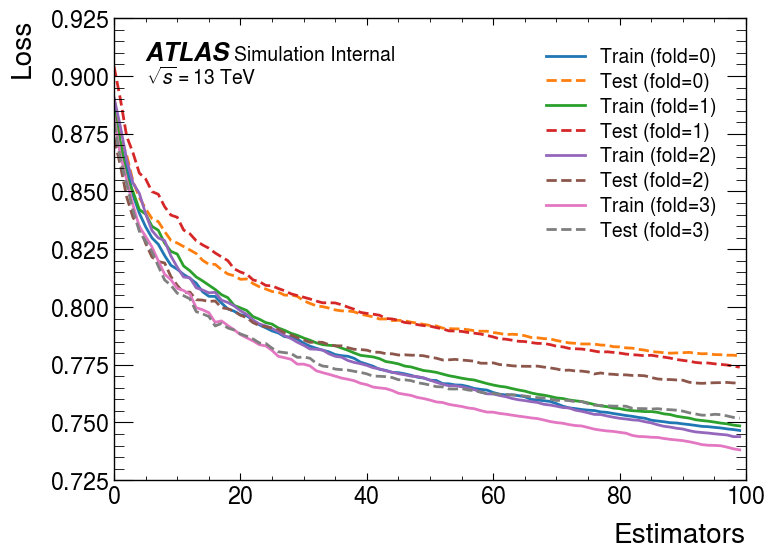

In [39]:
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [40]:
X_sig = df_sig_ttyy[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg_tty[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models_1on1]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models_1on1]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig_ttyy['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg_tty['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.4921813 , 0.35043597, 0.5944954 , ..., 0.54111236, 0.6745184 ,
       0.5742227 ], dtype=float32), array([0.40748462, 0.29674667, 0.5687395 , ..., 0.46093795, 0.51980937,
       0.5991263 ], dtype=float32), array([0.4070132 , 0.40127334, 0.7103624 , ..., 0.5247568 , 0.5902813 ,
       0.5761695 ], dtype=float32), array([0.40339288, 0.33491477, 0.62042177, ..., 0.49382347, 0.54039097,
       0.5634252 ], dtype=float32)]
Bkg:  [array([0.2613994 , 0.29835555, 0.46848312, ..., 0.09289577, 0.08820453,
       0.18841772], dtype=float32), array([0.24501237, 0.3390202 , 0.561804  , ..., 0.09105187, 0.07704092,
       0.26063398], dtype=float32), array([0.34588337, 0.3039306 , 0.51803464, ..., 0.11040342, 0.06766386,
       0.18743065], dtype=float32), array([0.21719824, 0.39625147, 0.506422  , ..., 0.10775833, 0.05490655,
       0.19880183], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3019


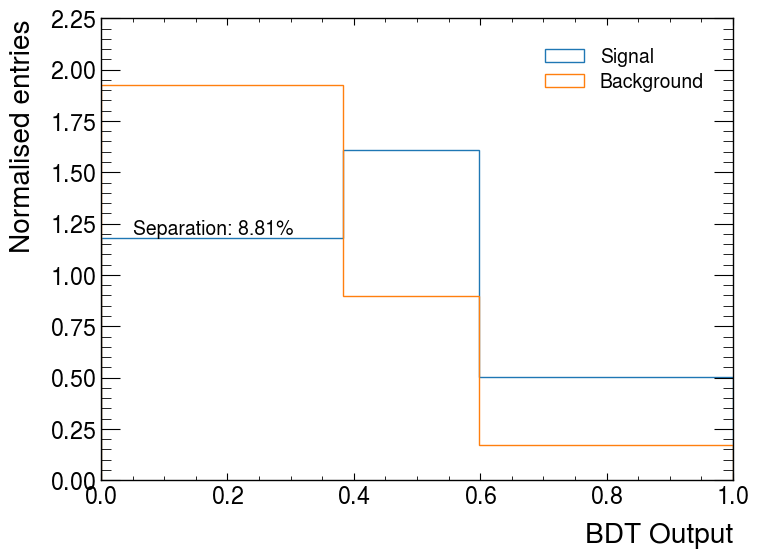

In [41]:
# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig_ttyy['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg_tty['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.2, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.png')
plt.legend()

In [45]:
# Current model with no reweighting - only for ttyy versus tty production
# SINGLE MODEL  : Using XGB Classifier
models_1on1 = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    # Select signal training set with positive weights
    sig_train_mask = (df_sig_ttyy['eventNumber'] % nfolds != fold) & (df_sig_ttyy['weight'] > 0)
    X_sig_train = df_sig_ttyy[feature_cols][sig_train_mask]
    w_sig_train = df_sig_ttyy['weight'][sig_train_mask]
    
    # Select signal test set with positive weights
    sig_test_mask = (df_sig_ttyy['eventNumber'] % nfolds == fold) & (df_sig_ttyy['weight'] > 0)
    X_sig_test = df_sig_ttyy[feature_cols][sig_test_mask]
    w_sig_test = df_sig_ttyy['weight'][sig_test_mask]

    # Select background training set with positive weights
    bkg_train_mask = (df_bkg_tty['eventNumber'] % nfolds != fold) & (df_bkg_tty['weight'] > 0)
    X_bkg_train = df_bkg_tty[feature_cols][bkg_train_mask]
    w_bkg_train = df_bkg_tty['weight'][bkg_train_mask]

    # Select background test set with positive weights
    bkg_test_mask = (df_bkg_tty['eventNumber'] % nfolds == fold) & (df_bkg_tty['weight'] > 0)
    X_bkg_test = df_bkg_tty[feature_cols][bkg_test_mask]
    w_bkg_test = df_bkg_tty['weight'][bkg_test_mask]
        
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    print("Signal train values:", X_sig_train[0:1])
    
    print("Lengths of train and test sets:")
    print("Signal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test(events,weights): ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    print("prediction train test: ", len(y_train), len(y_test))
    #print("prediction values: ", y_train[-100:], y_test[-100:])
    #print("concatenated train test: ", len(X_train), len(X_test))
    #print("concatenated train test values: ", X_train[0:2], X_test[0:2])

    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model_1on1 = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model_1on1.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models_1on1.append(model_1on1)
    scores_train.append(model_1on1.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model_1on1.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters_1on1 = len(models_1on1[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters_1on1)
    for i in range(n_boosters_1on1):
        ypred = models_1on1[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models_1on1[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    


Signal train values:         jet_pt[:,0]   jet_pt[:,1]       met_met  ph_eta[:,0]  ph_eta[:,1]  \
entry                                                                       
0      150484.40625  73511.679688  94067.289062    -0.810186    -2.244604   

         ph_pt[:,0]    ph_pt[:,1]  ph_mlph_closest[:,0]  ph_mlph_closest[:,1]  \
entry                                                                           
0      69320.984375  40159.082031           111921.4375          85738.242188   

             diph_M  event_nbjets70  dr_lep_ph0  dr_lep_ph1  \
entry                                                         
0      133776.86572               1    1.696234    2.024914   

       ph_conversion_type[:,1]  ph_conversion_type[:,0]  \
entry                                                     
0                            0                        0   

       ph_mphb70_closest[:,0]  ph_mphb70_closest[:,1]   m_AllObjects  \
entry                                                          

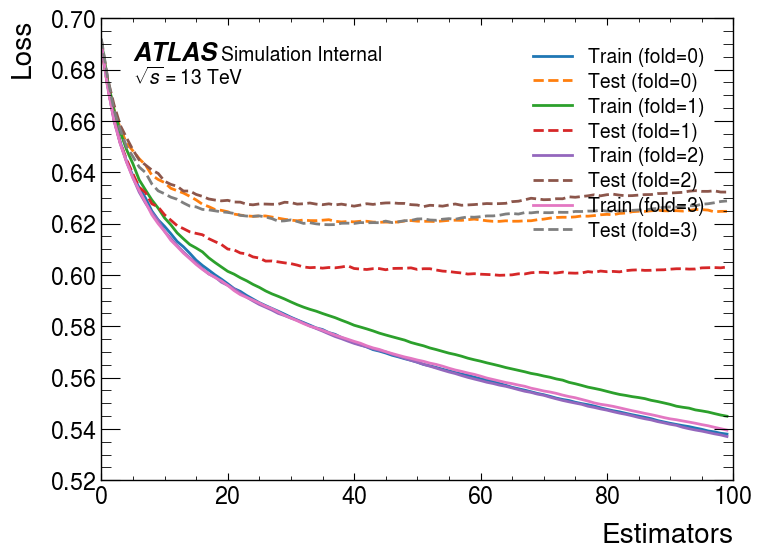

In [46]:
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [47]:
X_sig = df_sig_ttyy[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg_tty[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models_1on1]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models_1on1]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig_ttyy['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg_tty['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.72590905, 0.5841362 , 0.83374965, ..., 0.79468685, 0.8180001 ,
       0.844127  ], dtype=float32), array([0.70994097, 0.5367171 , 0.8181586 , ..., 0.730793  , 0.77103966,
       0.8115561 ], dtype=float32), array([0.7855202 , 0.681923  , 0.88174546, ..., 0.8050209 , 0.7636058 ,
       0.8450681 ], dtype=float32), array([0.7462387 , 0.6488966 , 0.8066493 , ..., 0.75920796, 0.75551516,
       0.7970931 ], dtype=float32)]
Bkg:  [array([0.514446  , 0.5625337 , 0.7830061 , ..., 0.33170146, 0.17684141,
       0.31597197], dtype=float32), array([0.5049559 , 0.5722301 , 0.7461847 , ..., 0.23342355, 0.17296305,
       0.36804202], dtype=float32), array([0.622524  , 0.57757294, 0.7413565 , ..., 0.2492007 , 0.14080669,
       0.3188283 ], dtype=float32), array([0.50373054, 0.66188586, 0.7646946 , ..., 0.27449322, 0.0980216 ,
       0.394795  ], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3019


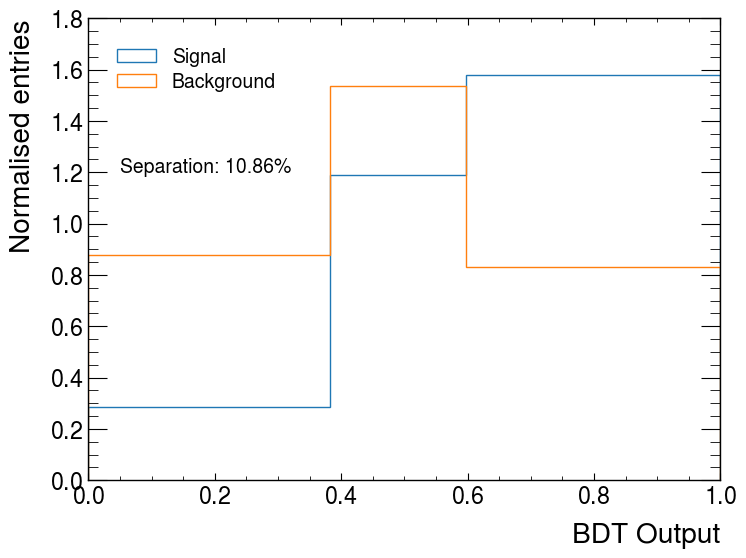

In [48]:
# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig_ttyy['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg_tty['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.2, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.png')
plt.legend()

In [18]:
# Current model with no reweighting
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg['weight'][df_bkg['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg['weight'][df_bkg['eventNumber']%nfolds == fold]
    
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    print("Signal train values:", X_sig_train[0:1])
    
    print("Lengths of train and test sets:")
    print("Signal train test(events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test(events,weights): ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    print("prediction train test: ", len(y_train), len(y_test))
    print("prediction values: ", y_train[-100:], y_test[-100:])
    #print("concatenated train test: ", len(X_train), len(X_test))
    #print("concatenated train test values: ", X_train[0:2], X_test[0:2])

    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

Signal train values:         jet_pt[:,0]   jet_pt[:,1]       met_met  ph_eta[:,0]  ph_eta[:,1]  \
entry                                                                       
0      150484.40625  73511.679688  94067.289062    -0.810186    -2.244604   

         ph_pt[:,0]    ph_pt[:,1]  ph_mlph_closest[:,0]  ph_mlph_closest[:,1]  \
entry                                                                           
0      69320.984375  40159.082031           111921.4375          85738.242188   

             diph_M  event_nbjets70  dr_lep_ph0  dr_lep_ph1  \
entry                                                         
0      133776.86572               1    1.696234    2.024914   

       ph_conversion_type[:,1]  ph_conversion_type[:,0]  \
entry                                                     
0                            0                        0   

       ph_mphb70_closest[:,0]  ph_mphb70_closest[:,1]   m_AllObjects  \
entry                                                          

Train scores 3: [0.7087981045544384, 0.7060952885656401, 0.7154218064399481, 0.7104624446638785]
Test scores 3:  [0.6040963733593898, 0.6508042671261003, 0.6147454002955082, 0.6280105900470212]
100


In [19]:
n_estimators = 100

# Class Reweighted
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg['weight'][df_bkg['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg['weight'][df_bkg['eventNumber']%nfolds == fold]
    
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    print("Lengths of train and test sets:")
    print("Signal train test: ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test: ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    print("prediction train test: ", len(y_train), len(y_test))
    print("concatenated train test: ", len(X_train), len(X_test))
    
    # Compute class weights based on the sum of sample weights
    sum_w_sig_train = np.sum(np.abs(w_sig_train))
    sum_w_bkg_train = np.sum(np.abs(w_bkg_train))
    
    print("Sum of weights for sig and bkg:", sum_w_sig_train, sum_w_bkg_train)
    
    total_weight = sum_w_sig_train + sum_w_bkg_train
    #class_weight_sig = total_weight / (2 * sum_w_sig_train)
    #class_weight_bkg = total_weight / (2 * sum_w_bkg_train)
    
    
    #print(f'Class weight for signal: {class_weight_sig}')
    #print(f'Class weight for background: {class_weight_bkg}')

    scale_pos_weight = sum_w_bkg_train / sum_w_sig_train
    print("Scaled weight:", scale_pos_weight )
    
    # Adjust sample weights
    #adjusted_sample_weights = np.where(y_train == 1, w_train * class_weight_sig, w_train * class_weight_bkg)
    
    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators, scale_pos_weight=scale_pos_weight) #scale_pos_weight (Optional[float]) – Balancing of positive and negative weights.
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

Lengths of train and test sets:
Signal train test:  243054 243054 80846 80846
Background train test:  2977 2977 982 982
prediction train test:  246031 81828
concatenated train test:  246031 81828
Sum of weights for sig and bkg: 30.665405 39.03958
Scaled weight: 1.2730821
Train scores 0: [0.7272803830623273]
Test scores 0:  [0.6165410822261359]
100
Lengths of train and test sets:
Signal train test:  242986 242986 80914 80914
Background train test:  3009 3009 950 950
prediction train test:  245995 81864
concatenated train test:  245995 81864
Sum of weights for sig and bkg: 30.681894 40.28777
Scaled weight: 1.3130796
Train scores 1: [0.7272803830623273, 0.7324068903576527]
Test scores 1:  [0.6165410822261359, 0.6704935632341031]
100
Lengths of train and test sets:
Signal train test:  242824 242824 81076 81076
Background train test:  2965 2965 994 994
prediction train test:  245789 82070
concatenated train test:  245789 82070
Sum of weights for sig and bkg: 30.654446 39.75639
Scaled weight

In [87]:
n_estimators = 100

# Class Reweighted
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg['weight'][df_bkg['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg['weight'][df_bkg['eventNumber']%nfolds == fold]
    
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    print("Lengths of train and test sets:")
    print("Signal train test: ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Background train test: ", len(X_bkg_train), len(w_bkg_train), len(X_bkg_test), len(w_bkg_test))
    
    print("prediction train test: ", len(y_train), len(y_test))
    print("concatenated train test: ", len(X_train), len(X_test))
    
    # Compute class weights based on the sum of sample weights
    sum_w_sig_train = np.sum(np.abs(w_sig_train))
    sum_w_bkg_train = np.sum(np.abs(w_bkg_train))
    
    print("Sum of weights for sig and bkg:", sum_w_sig_train, sum_w_bkg_train)
    
    total_weight = sum_w_sig_train + sum_w_bkg_train
    #class_weight_sig = total_weight / (2 * sum_w_sig_train)
    #class_weight_bkg = total_weight / (2 * sum_w_bkg_train)
    
    
    #print(f'Class weight for signal: {class_weight_sig}')
    #print(f'Class weight for background: {class_weight_bkg}')

    scale_pos_weight = sum_w_bkg_train / sum_w_sig_train
    print("Scaled weight:", scale_pos_weight )
    
    # Adjust sample weights
    #adjusted_sample_weights = np.where(y_train == 1, w_train * class_weight_sig, w_train * class_weight_bkg)
    
    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators, scale_pos_weight=scale_pos_weight) #scale_pos_weight (Optional[float]) – Balancing of positive and negative weights.
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

Lengths of train and test sets:
Signal train test:  256585 256585 85396 85396
Background train test:  3433 3433 1129 1129
prediction train test:  260018 86525
concatenated train test:  260018 86525
Sum of weights for sig and bkg: 32.410686 44.968956
Scaled weight: 1.3874731
Train scores 0: [0.743474175641234]
Test scores 0:  [0.6351372702219076]
100
Lengths of train and test sets:
Signal train test:  256576 256576 85405 85405
Background train test:  3447 3447 1115 1115
prediction train test:  260023 86520
concatenated train test:  260023 86520
Sum of weights for sig and bkg: 32.443596 45.77355
Scaled weight: 1.4108654
Train scores 1: [0.743474175641234, 0.7466435744654719]
Test scores 1:  [0.6351372702219076, 0.6790581841211893]
100
Lengths of train and test sets:
Signal train test:  256423 256423 85558 85558
Background train test:  3421 3421 1141 1141
prediction train test:  259844 86699
concatenated train test:  259844 86699
Sum of weights for sig and bkg: 32.41378 45.122684
Scaled w

In [23]:
mplhep.style.use('ATLAS')

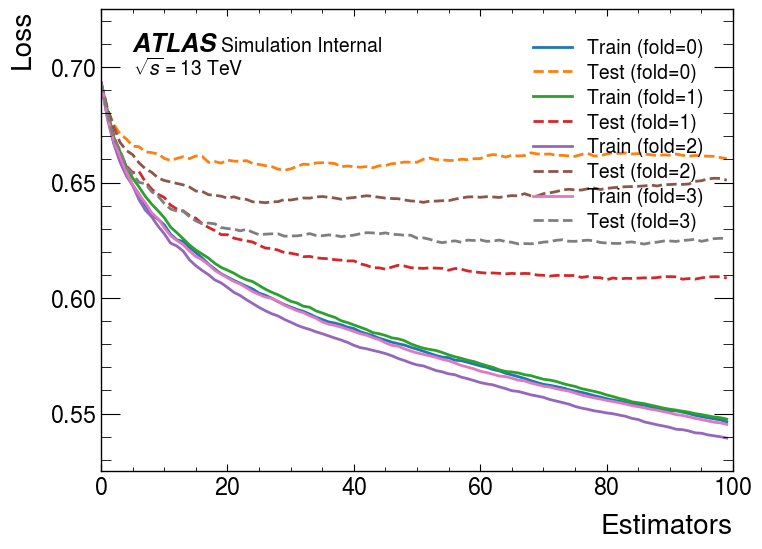

In [24]:
    
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [8]:
# Loss curve from pickle file, actual:
#nfolds = 4
#models = []

#for fold in range(nfolds):
#    with open(f'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'rb') as f:
#        model = pickle.load(f)
#        models.append(model)

In [21]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.50946015, 0.62892497, 0.8062524 , ..., 0.83878237, 0.8260537 ,
       0.5935211 ], dtype=float32), array([0.6364469 , 0.6236927 , 0.78419113, ..., 0.7773488 , 0.79013604,
       0.5669986 ], dtype=float32), array([0.60585755, 0.74241185, 0.82529193, ..., 0.8355823 , 0.7747182 ,
       0.6654055 ], dtype=float32), array([0.5438862 , 0.7443601 , 0.79676074, ..., 0.8177008 , 0.8172533 ,
       0.6928123 ], dtype=float32)]
Bkg:  [array([0.44804502, 0.6211904 , 0.8169516 , ..., 0.72051054, 0.25911406,
       0.7863    ], dtype=float32), array([0.38976747, 0.61733323, 0.7626227 , ..., 0.1363898 , 0.46245572,
       0.7655841 ], dtype=float32), array([0.5366792 , 0.67685574, 0.7280533 , ..., 0.12510954, 0.32217434,
       0.669494  ], dtype=float32), array([0.51176745, 0.6873107 , 0.7973581 , ..., 0.14340346, 0.5987551 ,
       0.7492896 ], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3959


sig histogram values:  [0.00371578 0.15695241 0.48521586 0.80169708 1.15422157 1.53145768
 1.90156573 2.11590311 1.6251558  0.22411505]


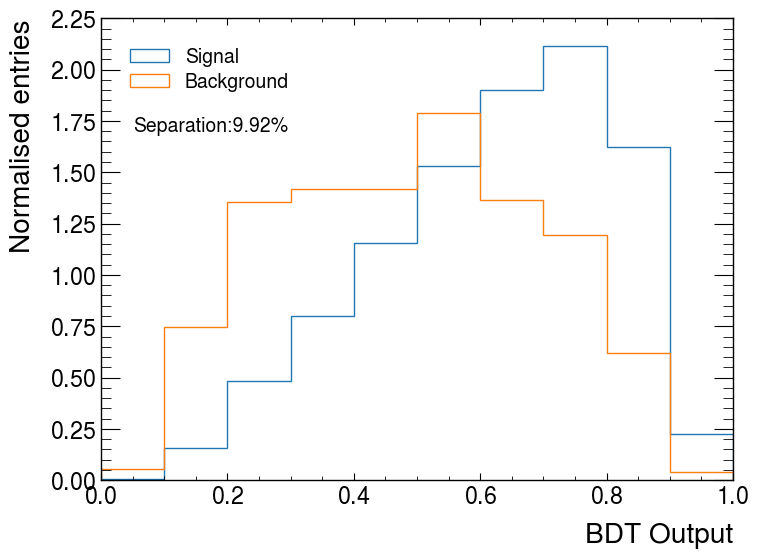

In [27]:
# Considering Negative Weights
nbins = 10
bc_sig,_,_ = plt.hist(results_sig, weights=(df_sig['weight']),  range=(0,1), bins=nbins, histtype='step', density=True, label='Signal')
bc_bkg,_,_ = plt.hist(results_bkg, weights=(df_bkg['weight']), range=(0,1), bins=nbins, histtype='step', density=True, label='Background')
print('sig histogram values: ',bc_sig )
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig/nbins - bc_bkg/nbins) ** 2) / (bc_sig/nbins + bc_bkg/nbins)))

plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
#mplhep.atlas.label('WIP', data=False, ax=ax)
plt.text(x=0.05, y=1.7,s=F'Separation:{separation*100:.2f}%')

plt.legend()

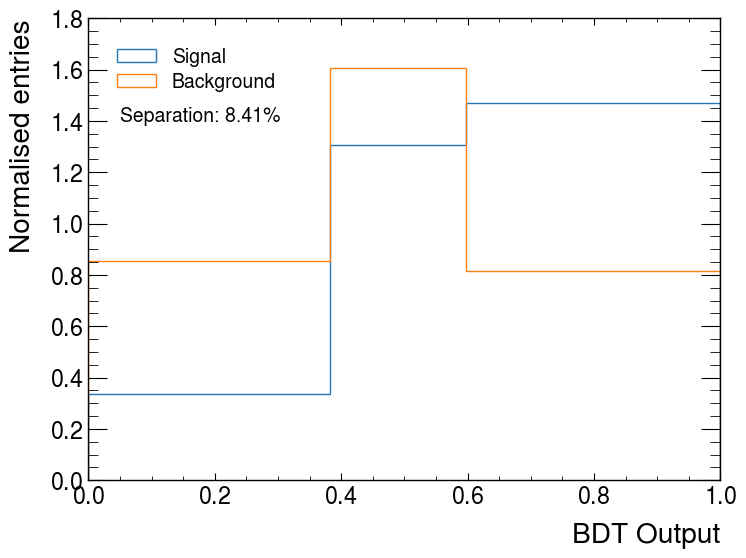

In [29]:
# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.4, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.png')
plt.legend()

In [40]:
for i, model in enumerate(models):
    # Assuming model[0] has the feature importance scores
    feature_importances = models[i].feature_importances_

    # Create a list of tuples with feature name and importance
    feature_imp_list = zip(feature_cols, feature_importances)
    print(feature_imp_list) 
    # Sort the list based on importance in ascending order (key=lambda x: x[1])
    sorted_features = sorted(feature_imp_list, key=lambda x: x[1])
    print(f'for model: {i}')
    # Print the sorted features
    for feature, importance in sorted_features:
        print(f"Feature Name: {feature}, Importance: {importance}")
        
    print(F"No. of features: {len(sorted_features)}")

for model: 0
Feature Name: ph_pt[:,0], Importance: 0.018416868522763252
Feature Name: ph_e[:,0], Importance: 0.022075023502111435
Feature Name: ph_eta[:,0], Importance: 0.023032937198877335
Feature Name: met_met, Importance: 0.024034254252910614
Feature Name: ph_mlph_closest[:,0], Importance: 0.025007551535964012
Feature Name: jet_pt[:,0], Importance: 0.025959305465221405
Feature Name: ph_pt[:,1], Importance: 0.02616032399237156
Feature Name: ph_mphb77_closest[:,0], Importance: 0.026467816904187202
Feature Name: jet_pt[:,1], Importance: 0.026606183499097824
Feature Name: m_AllObjects, Importance: 0.026777643710374832
Feature Name: diph_M, Importance: 0.026932038366794586
Feature Name: event_nbjets77, Importance: 0.029088474810123444
Feature Name: ph_mphb77_closest[:,1], Importance: 0.031529512256383896
Feature Name: ph_e[:,1], Importance: 0.03262396901845932
Feature Name: dr_lep_ph0, Importance: 0.036533281207084656
Feature Name: ph_eta[:,1], Importance: 0.04314335808157921
Feature Nam

Features with Average Importance (Descending):
Feature Name: ph_conversion_type[:,0], Average Importance: 0.20215236395597458
Feature Name: ph_conversion_type[:,1], Average Importance: 0.1532019004225731
Feature Name: ph_mlph_closest[:,1], Average Importance: 0.062062869779765606
Feature Name: dr_lep_ph1, Average Importance: 0.05693809874355793
Feature Name: jet_DL1r_bjetscore, Average Importance: 0.05624716356396675
Feature Name: event_nbjets77, Average Importance: 0.04726755153387785
Feature Name: ph_eta[:,1], Average Importance: 0.035908560268580914
Feature Name: dr_lep_ph0, Average Importance: 0.034355022478848696
Feature Name: jet_pt[:,0], Average Importance: 0.031916366424411535
Feature Name: ph_mphb77_closest[:,0], Average Importance: 0.03164380835369229
Feature Name: ph_e[:,1], Average Importance: 0.031339592300355434
Feature Name: m_AllObjects, Average Importance: 0.030031325295567513
Feature Name: diph_M, Average Importance: 0.02836584858596325
Feature Name: ph_pt[:,1], Avera

<Figure size 3000x3600 with 0 Axes>

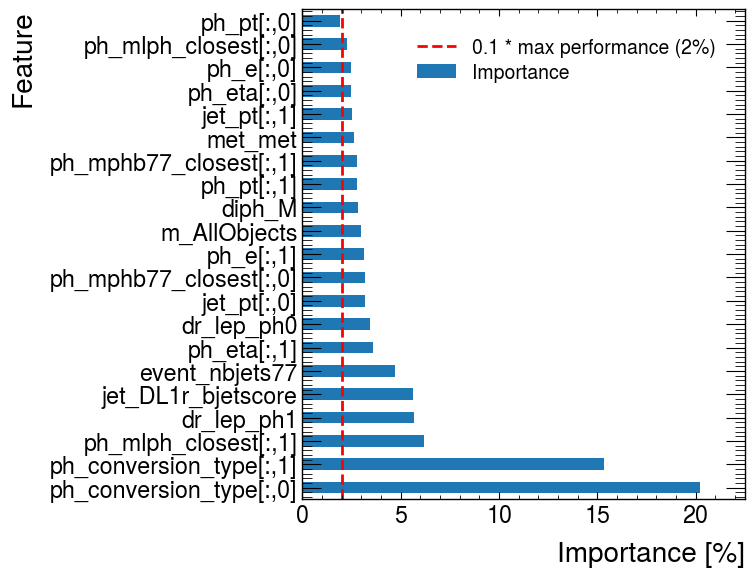

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

def average_feature_importances(models, feature_cols):
  """
  This function calculates the average importance for each feature across all folds/models.

  Args:
      models: A list of XGBoost classifier models.
      feature_cols: A list of feature column names.

  Returns:
      A dictionary containing feature name and its average importance across all folds.
  """
  # Initialize a dictionary to store average importance
  average_importances = {feature: 0.0 for feature in feature_cols}

  # Iterate through each model and accumulate importance for each feature
  for model in models:
    importance_scores = model.feature_importances_  # Access feature importance attribute
    for feature, importance in zip(feature_cols, importance_scores):
      average_importances[feature] += importance

  # Calculate average importance by dividing by the total number of models
  num_models = len(models)
  for feature in average_importances:
    average_importances[feature] /= num_models

  # Sort features by importance in descending order
  sorted_importances = sorted(average_importances.items(), key=lambda x: x[1], reverse=True)
  return sorted_importances

# Assuming models and feature_cols are available (replace with your actual data)
average_importances = average_feature_importances(models, feature_cols)

# Print features with average importance (sorted by descending importance)
print("Features with Average Importance (Descending):")
for feature, importance in average_importances:
  print(f"Feature Name: {feature}, Average Importance: {importance}")

# Create DataFrame from sorted importance and plot as horizontal bar chart
importance_df = pd.DataFrame(average_importances, columns=['Feature', 'Importance'])
importance_df['Importance'] *= 100  # Scale importance to percentage

plt.figure(figsize=(30, 36))
importance_df.set_index('Feature').plot.barh(legend=False)
plt.xlabel('Importance [%]')

# Optional: Add a threshold line (adjust threshold value as needed)
plt.axvline(2.0, color='red', linestyle='--', label='0.1 * max performance (2%)')
plt.legend()
#plt.savefig(f'Feature_importance_average.png')

plt.tight_layout()
plt.show()


(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

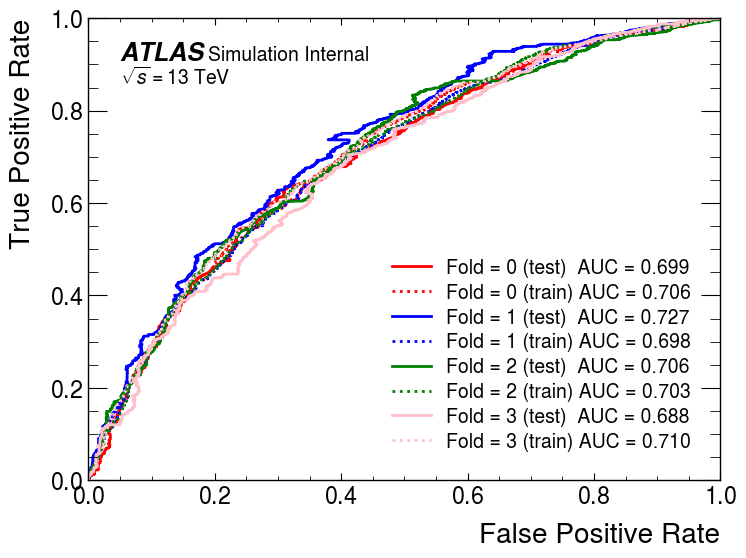

In [94]:
folds = 4
#fig, axes = plt.subplots(nrows=2,ncols=2, figsize=(12,10))
#axes = axes.reshape(-1)
colors = ['red','blue','green','pink'] 
for fold in range(folds):
    results_sig_fold_test = results_sig[df_sig['eventNumber']%folds == fold]
    results_bkg_fold_test = results_bkg[df_bkg['eventNumber']%folds == fold]
    weights_sig_fold_test = df_sig['weight'][df_sig['eventNumber']%folds == fold]
    weights_bkg_fold_test = df_bkg['weight'][df_bkg['eventNumber']%folds == fold]
    y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
    scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
    weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])
    fpr, tpr, thresholds = metrics.roc_curve(y, scores, sample_weight=weights,pos_label=1)
    #AUC = metrics.roc_auc_score(y, scores)
    AUC = trapezoid(y=tpr,x=fpr)
    plt.plot(fpr,tpr,label=F'Fold = {fold} (test)  AUC = {AUC:.3f}', color=colors[fold])
    
    results_sig_fold_train = results_sig[df_sig['eventNumber']%folds != fold]
    results_bkg_fold_train = results_bkg[df_bkg['eventNumber']%folds != fold]
    weights_sig_fold_train = df_sig['weight'][df_sig['eventNumber']%folds != fold]
    weights_bkg_fold_train = df_bkg['weight'][df_bkg['eventNumber']%folds != fold]
    y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
    scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
    weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])
    fpr, tpr, thresholds = metrics.roc_curve(y, scores, sample_weight=weights, pos_label=1)
    AUC = trapezoid(y=tpr,x=fpr)
    plt.plot(fpr,tpr,label=F'Fold = {fold} (train) AUC = {AUC:.3f}', color=colors[fold], linestyle='dotted')

plt.legend()
plt.xlim(0,1)
plt.ylim(0,1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)   # true to remove Simulation

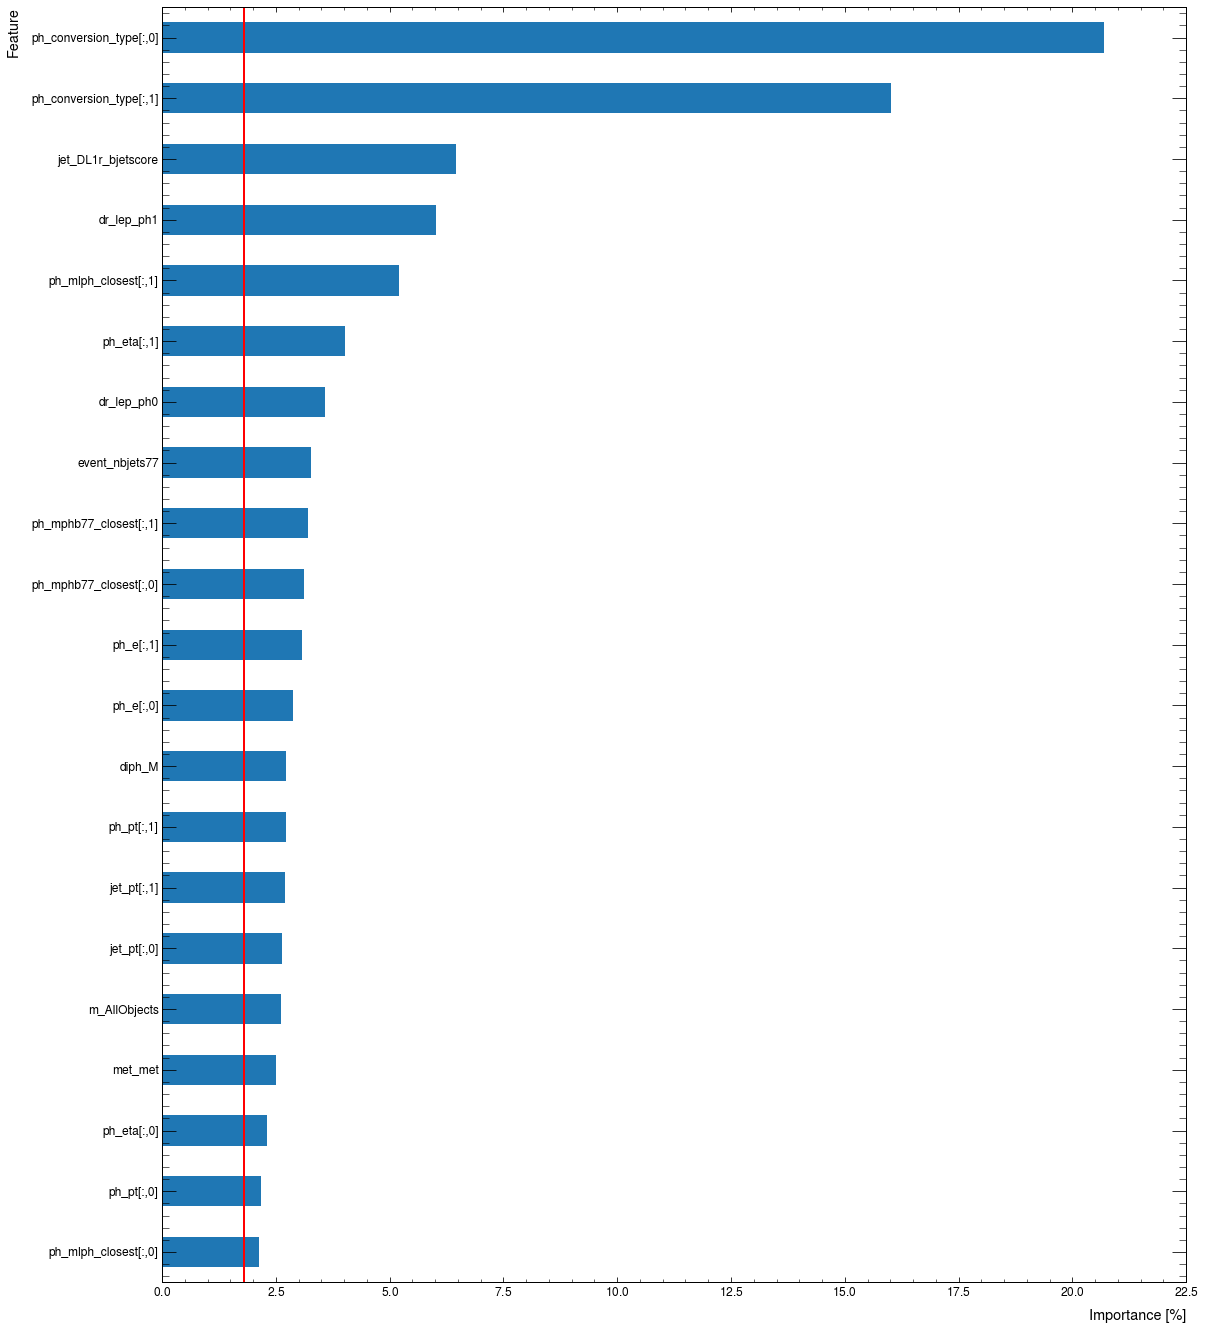

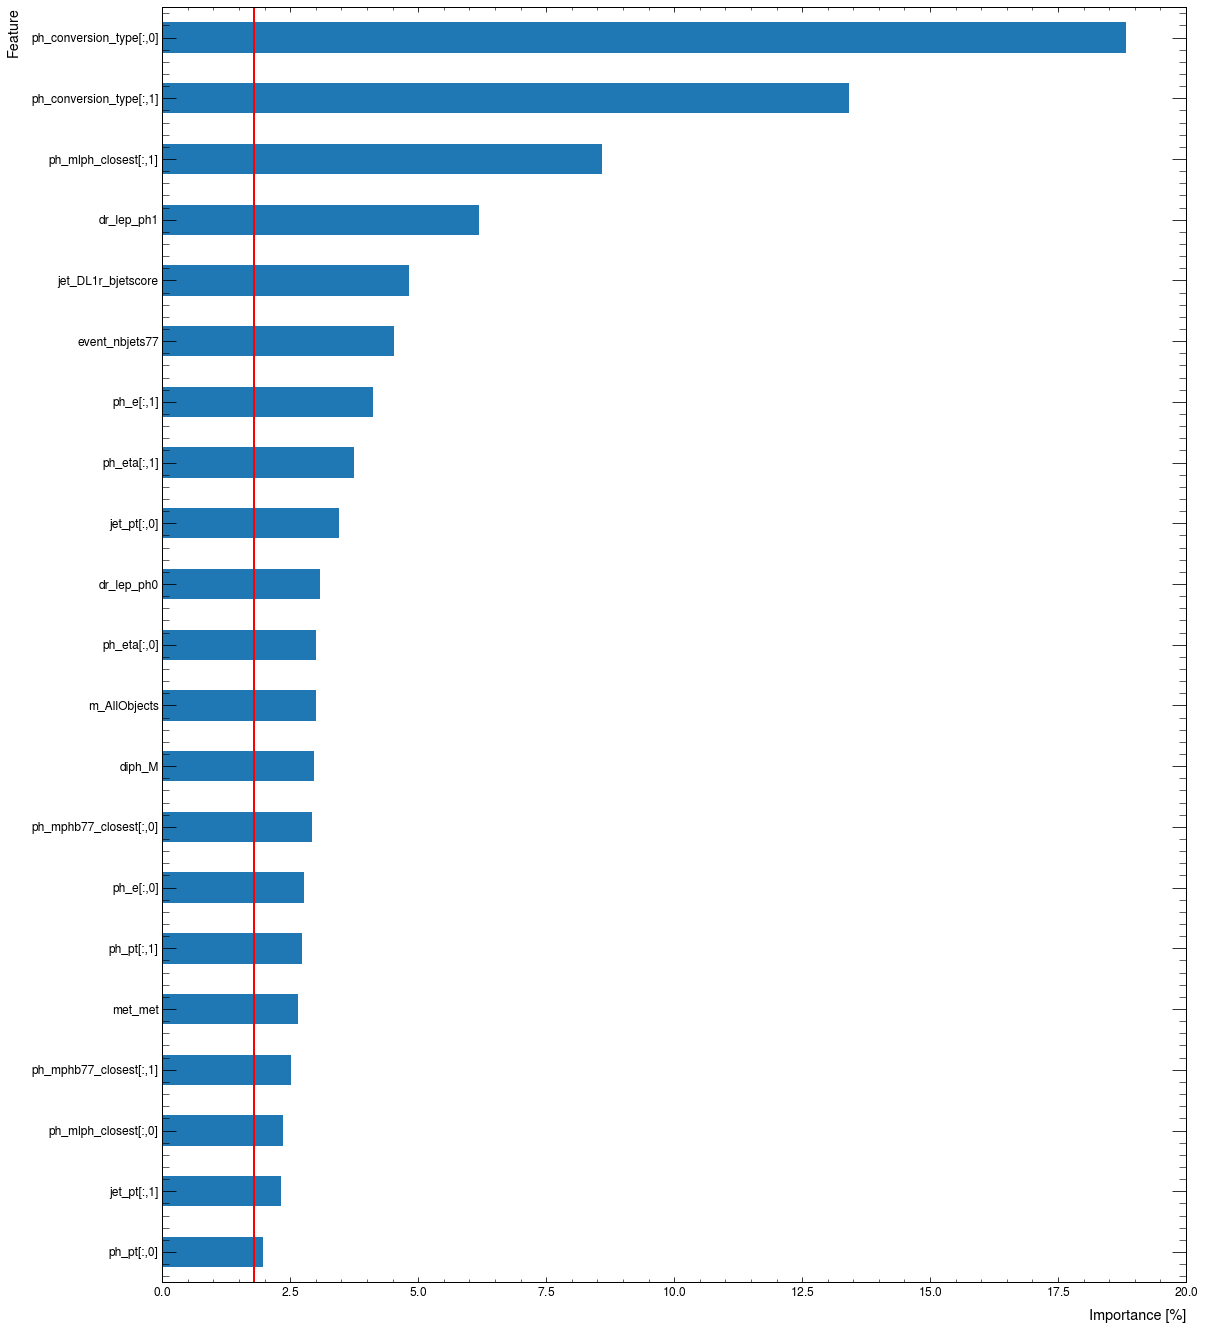

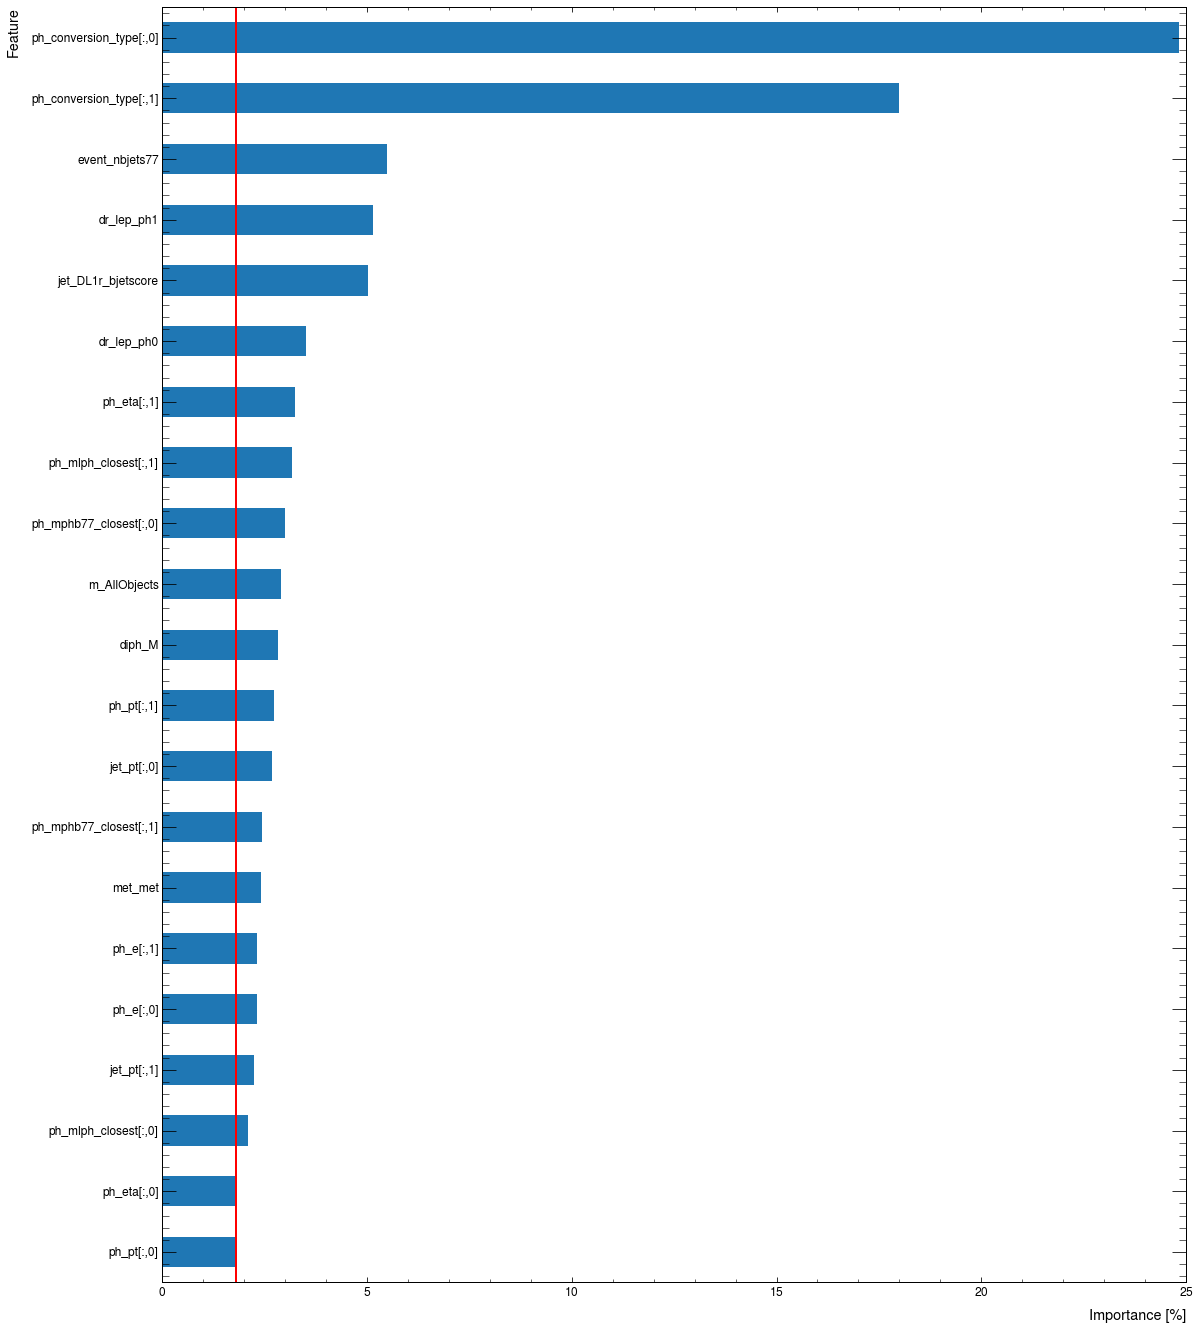

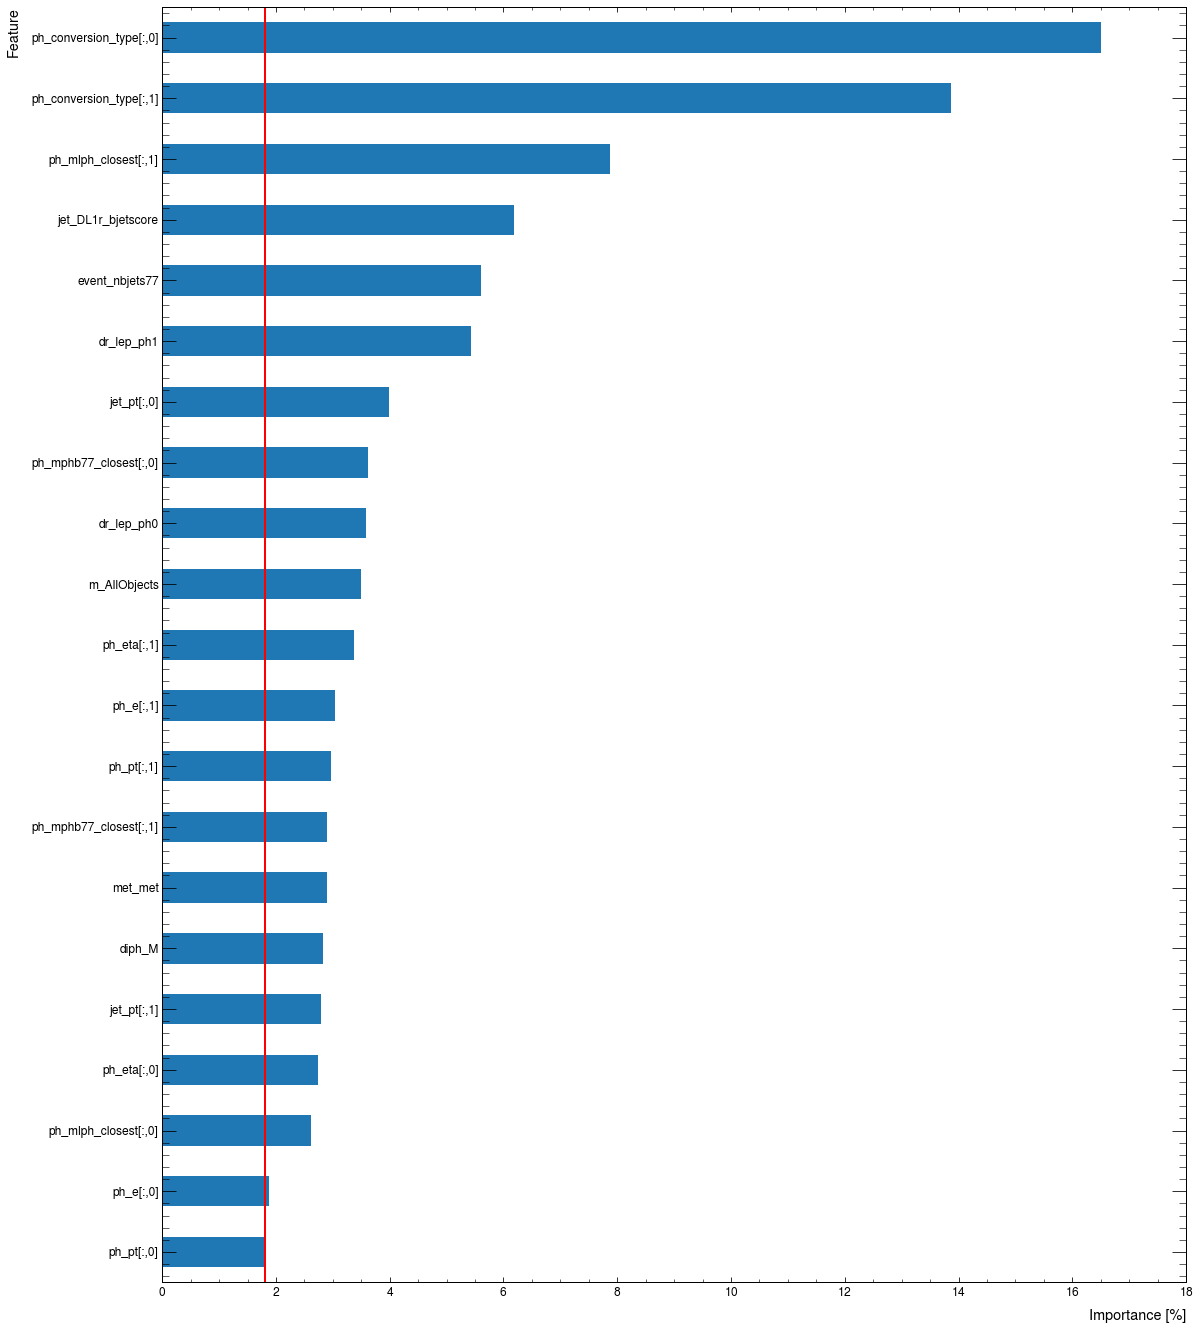

In [11]:
for fold in range(4):
    feature_importances = models[fold].feature_importances_
    feature_imp_list = zip(feature_cols, feature_importances)

    sorted_features = sorted(feature_imp_list, key=lambda x: x[1])
    df = pd.DataFrame(sorted_features, columns = ['Feature','Importance'])
    df['Importance'] = df['Importance'] * 100
    df.set_index('Feature').plot.barh(legend=False, figsize=(18,22))
    plt.xlabel('Importance [%]')
    plt.axvline(1.8,color='red')
    #plt.savefig(f'Feature_importance_{fold}.png')

In [ ]:
for fold in range(4):
    feature_importances = models[fold].feature_importances_
    feature_imp_list = zip(feature_cols, feature_importances)

    sorted_features = sorted(feature_imp_list, key=lambda x: x[1])
    df = pd.DataFrame(sorted_features, columns = ['Feature','Importance'])
    df['Importance'] = df['Importance'] * 100
    df.set_index('Feature').plot.barh(legend=False, figsize=(18,22))
    plt.xlabel('Importance [%]')
    plt.axvline(1.8,color='red')
   

In [28]:
len(results_sig_fold_train)

256585

In [55]:
bkg_corr_matrix = df_bkg[feature_cols].corr()
#bkg_corr_matrix.to_csv('bkg_correlation_matrix.csv', index=True)  # Save to CSV
sig_corr_matrix = df_sig[feature_cols].corr()


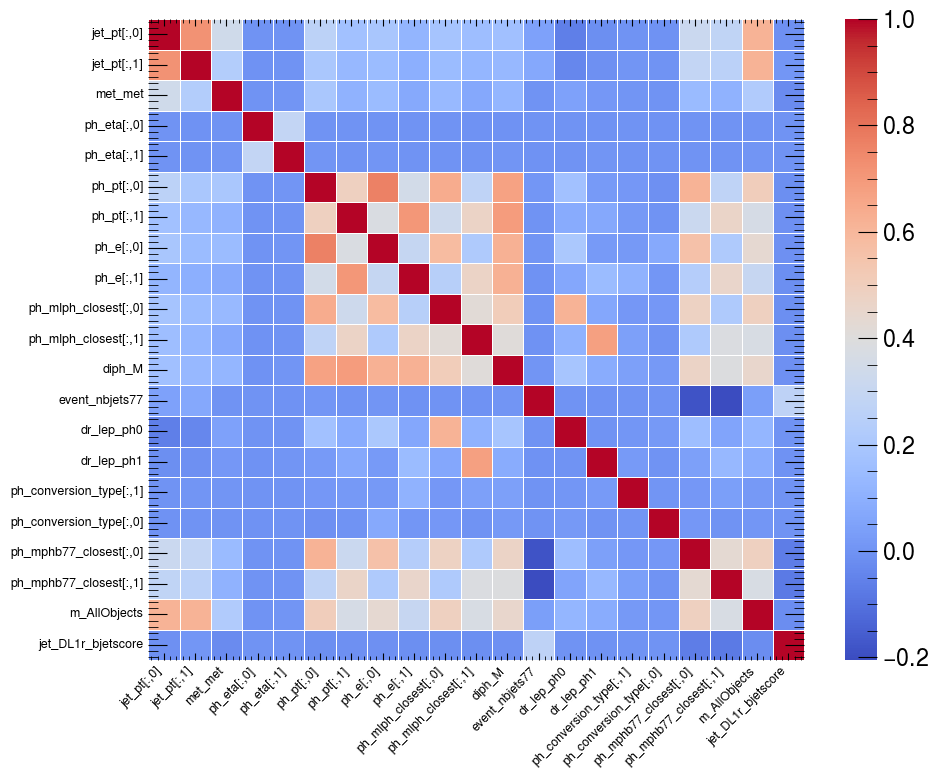

In [60]:

# Increase figure size for a large heatmap
plt.figure(figsize=(10, 8))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
sns.heatmap(sig_corr_matrix, cmap='coolwarm', linewidths=0.5, cbar=True, facecolor='white')

# Reduce text label clutter (optional)
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)

plt.tight_layout()
#plt.savefig('sig_correlation_heatmap_seaborn_large_white.png', dpi=500, bbox_inches='tight')
plt.show()  # Optional: Comment out if you only want to save the image


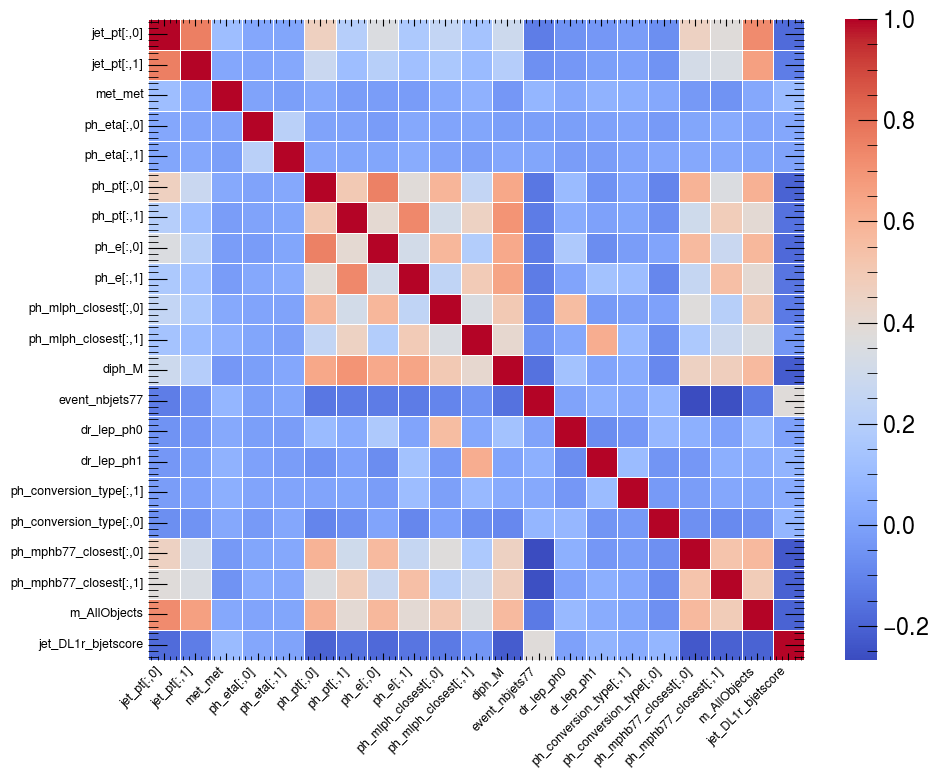

In [61]:

# Increase figure size for a large heatmap
plt.figure(figsize=(10, 8))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
sns.heatmap(bkg_corr_matrix, cmap='coolwarm', linewidths=0.5, cbar=True, facecolor='white')

# Reduce text label clutter (optional)
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)

plt.tight_layout()
#plt.savefig('bkg_correlation_heatmap_seaborn_large_white.png', dpi=500, bbox_inches='tight')
plt.show()  # Optional: Comment out if you only want to save the image



 --------------------Fold:  0 --------------------
Sig min max:  0.02510735809407366 1.8308223412666589
Bkg min max:  0.01916693914209475 1.8085797279115206

Signal train histogram: [0.02510736 0.34662521 0.75826331 1.12687924 1.43356057 1.68269399
 1.83082234 1.72179672 0.98551104 0.08873935]
Signal test histogram: [0.01916694 0.34808914 0.78316465 1.14759439 1.44110939 1.64843168
 1.80857973 1.70515283 1.00341169 0.09529937]
Background train histogram: [0.23236851 1.38158304 1.67964342 1.94850284 1.32971417 1.35003567
 1.19140954 0.56886285 0.2807774  0.03710316]
Background test histogram: [0.17709553 1.05420454 2.22170546 1.54788489 1.72318905 1.52651382
 0.71481211 0.64419598 0.3822742  0.00812466]

 Ratio:
Sig:  [1.3099305  0.99579439 0.96820421 0.98194907 0.9947618  1.0207848
 1.01229839 1.00976094 0.98216021 0.93116408]
Bkg:  [1.31210829 1.31054551 0.75601535 1.25881637 0.7716589  0.88439138
 1.66674505 0.88305867 0.73449216 4.56673463]

 --------------------Fold:  1 ----------

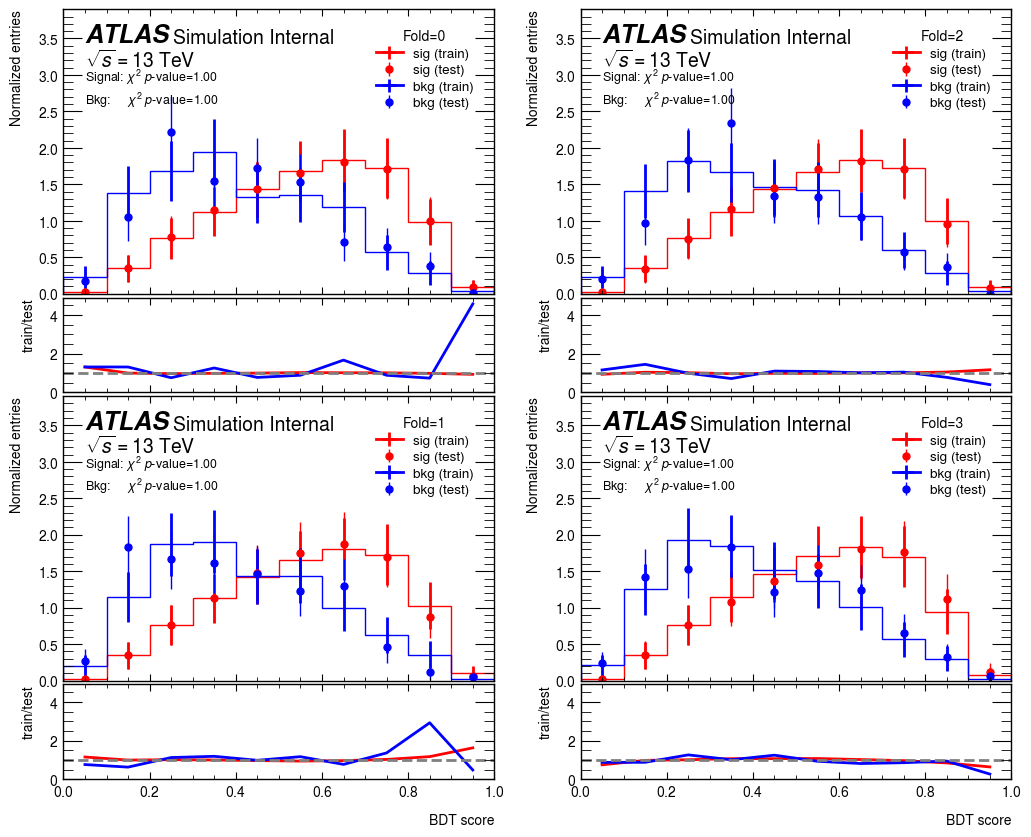

In [14]:
##### Redundant Code - IGNORE!!!   ######
######                             ######

folds = 4
#fig, axes = plt.subplots(folds * 2, 1, figsize=(10, 15), gridspec_kw={'height_ratios': [3, 1] * folds})
fig, axes = plt.subplots(nrows=4,ncols=2,gridspec_kw={'height_ratios': [3,1,3,1]}, sharex=True, figsize=(12, 10))
axes = axes.ravel(order='F')  # Reshape into (folds, 2) to handle two plots per fold

# Process data and plot in each fold's respective axis
for fold in range(folds):
    ax = axes[2*fold]  # Main plot for current fold
    ax_ratio = axes[2*fold+1]  # Ratio plot for current fold
    #print(ax,ax_ratio)
    print("\n --------------------Fold: ", fold, "--------------------")
    
    # Example dummy data and plots:
    results_sig_fold_test = results_sig[df_sig['eventNumber']%folds == fold]
    results_bkg_fold_test = results_bkg[df_bkg['eventNumber']%folds == fold]
    weights_sig_fold_test = df_sig['weight'][df_sig['eventNumber']%folds == fold]
    weights_bkg_fold_test = df_bkg['weight'][df_bkg['eventNumber']%folds == fold]
    y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
    scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
    weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

    results_sig_fold_train = results_sig[df_sig['eventNumber']%folds != fold]
    results_bkg_fold_train = results_bkg[df_bkg['eventNumber']%folds != fold]
    weights_sig_fold_train = df_sig['weight'][df_sig['eventNumber']%folds != fold]
    weights_bkg_fold_train = df_bkg['weight'][df_bkg['eventNumber']%folds != fold]
    y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
    scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
    weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])
    
    bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=10, density=True)
    mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(bc_sig_train/10), label='sig (train)', histtype='step', ax=ax, color='red')
    bc_sig_test, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test,range=(0,1), bins=10, density=True)
    mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(bc_sig_test/10),label='sig (test)', histtype='errorbar', ax=ax, color='red')
    
    bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=10, density=True)
    mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(bc_bkg_train/10), label='bkg (train)', histtype='step', ax=ax, color='blue')
    bc_bkg_test, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test,range=(0,1), bins=10, density=True)
    mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(bc_bkg_test/10),label='bkg (test)', histtype='errorbar', ax=ax, color='blue')
    # Example check if data is within expected range
    #print("minimum and maximum values(sig,bkg):\n")
    print('Sig min max: ', bc_sig_train.min(), bc_sig_train.max())
    print('Bkg min max: ', bc_sig_test.min(), bc_sig_test.max())
    #print(len(bb), len(bc_sig_train), len(bc_bkg_train))
    
    bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)

    corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
    chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
    corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
    chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)

    ax.set_xlim(0,1)
    ax.set_ylim(0,3.9)
      

    #ax.set_xlabel('BDT score')
 
    ax.set_ylabel('Normalized entries', fontsize=10)
    mplhep.atlas.label('Internal', data=False, ax=ax)
    ax.text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}', fontsize=9)
    ax.legend(title=F'Fold={fold}', loc='upper right',fontsize='x-small', title_fontsize=10)
    ax.tick_params(axis='both', labelsize=10)

    print("\nSignal train histogram:", bc_sig_train)
    print("Signal test histogram:", bc_sig_test)
    print("Background train histogram:", bc_bkg_train)
    print("Background test histogram:", bc_bkg_test)

    #print(type(bc_bkg_test))
    list_histograms = [bc_sig_train, bc_sig_test, bc_bkg_train, bc_bkg_test]
    #print("Length: ")

   # for hist in list_histograms:  # Loop through each histogram
   #     for j, value in enumerate(hist):  # Loop through elements with index and value
   #         if value == 0.:
   #             hist[j] = 1e-6  # Modify the element directly using its index
   #             print(f"Replaced 0 at index {j} in histogram")

    #if bc_bkg_test[9] == 0.:
    #    print("YESSS!! A 0 here")
    #    bc_bkg_test[9] = 1e-3

    #bc_bkg_test[9] =  1e-6 
    
    
                
    ratio_sig = np.where(bc_sig_test == 0, 1e-1, bc_sig_train / bc_sig_test)
    ratio_bkg = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_train / bc_bkg_test)

    print("\n Ratio:")
    # Ratio plot
    #ratio_sig = bc_sig_train/bc_sig_test # np.divide(bc_sig_train, bc_sig_test, out=np.zeros_like(bc_sig_train), where=bc_sig_test != 0)
    #ratio_bkg = bc_bkg_train/bc_bkg_test #  np.divide(bc_bkg_train, bc_bkg_test, out=np.zeros_like(bc_bkg_train), where=bc_bkg_test != 0)
    #print(bb)
    print("Sig: ", ratio_sig)
    print("Bkg: ", ratio_bkg)
    #print(len(bb), len(ratio_sig), len(ratio_bkg))
  

    # Issue a warning if there are any zeros in bc_bkg_test
    if np.any(bc_bkg_test == 0):
        warnings.warn("Division by zero encountered in bc_bkg_test. Results might be inaccurate.")
                
    
    bb_centers = (bb[:-1] + bb[1:]) / 2
    #print(bb_centers)
    ax_ratio.plot(bb_centers, ratio_sig, label='Ratio Sig',color='red')
    ax_ratio.plot(bb_centers, ratio_bkg, label='Ratio Bkg', color='blue')
    ax_ratio.axhline(1,0,1,linestyle='--',color='grey')
    

    ax_ratio.set_ylabel('train/test', fontsize=10)
    ax_ratio.set_xlabel('BDT score', fontsize=10)
    ax_ratio.set_ylim(0., 4.9)  # Adjust based on your ratio values
    ax_ratio.tick_params(axis='both', labelsize=10)
    
# Configure the layout to avoid overlap
fig.subplots_adjust(hspace=0.02)  # Adjust horizontal space if needed
#fig.tight_layout()
fig.show()

In [30]:
#hi

In [32]:
xgboost.__version__

'2.0.2'